# Does the Agent Watch Its Oxygen?

**An explainability study of a pretrained Seaquest agent**  
QIAN Yuwei and JIN Yupeng

**Final report**

The benchmark retained all three methods after testing them on 120 decisions. Every eligible input in the original 20 analysis games also appeared in the selection games. With sticky actions (probability 0.25), 20 new games yielded 300 isolated inputs. Across oxygen strata, blacking out the neighboring HUD weakened action support more than blacking out the gauge. With blur, the gauge had the larger effect. Two life-loss cases had different lead-ups and an unknown cause.

## Research questions

- **RQ1.** Which explanation method is most faithful to the agent's action preferences under the declared protocol?
- **RQ2.** How does the agent's decision-specific reliance on the oxygen gauge vary with oxygen level?
- **RQ3.** What patterns appear before life loss?

## Task, model and decision states

In Atari Seaquest, a submarine rescues divers, evades enemies and surfaces to replenish oxygen [2]. We evaluate the public [`sb3/dqn-SeaquestNoFrameskip-v4` checkpoint](https://huggingface.co/sb3/dqn-SeaquestNoFrameskip-v4). We load its weights strictly with `weights_only=True` and run inference in evaluation mode on one CPU thread with fixed weights.

The original environment, `ALE/Seaquest-v5` [2], uses frame skip 1, zero sticky-action probability and all 18 actions. The Stable-Baselines3 (SB3) Atari wrapper [1] repeats each action up to four emulator steps, max-pools the last two frames and produces an 84 × 84 grayscale observation. The policy receives a stack of four observations, oldest first, with reset observation copies until four real frames exist. It acts greedily, breaking exact Q ties by the lowest index.

The wrapper uses seeded no-ops and a FIRE/UP reset. Full-game scores sum unclipped rewards from recorded policy actions. An individual life loss leaves the episode and frame history running. For each zero-based decision, Q-values, the chosen action, the frame stack and RAM metadata are pre-action. Reward, next lives and termination flags are post-action. For analysis we record oxygen (RAM[102]), depth (RAM[97]) and divers (RAM[62]) from the OCAtari mapping [3], plus the raw animation byte (RAM[105]). The policy sees only pixels.

## Experimental samples

| Question | Games and observations |
| --- | --- |
| RQ1 method selection | 120 decisions across 10 original games |
| RQ2 original held-out split | 0/300 eligible after checking all raw selection inputs |
| RQ2 exploratory supplement | 297 revisited decisions across 20 original games |
| RQ2 sticky-action follow-up | 300 isolated inputs across 20 new games, 100 per oxygen stratum |
| RQ3 life loss | Two exploratory event–control pairs from the original analysis games |


## Selection sampling and achieved coverage

We fixed the seed split before collection (commit `6da8ce4`). Seeds 1000-1009 are for method selection and 1010-1029 are assigned to analysis. The selection target is 120 states, four in each stratum per game. The held-out target is 300 states from twenty games. General faithfulness comparisons use only the ten selection games.

Low, medium and high oxygen are 1-15, 16-44 and 45-64, using the latest pre-action reading. All four frames must pass the history filter. It excludes reset padding, frames within the first 20 decisions or within 20 decisions after a life loss, oxygen outside 1-64, nonzero pre- or post-action animation bytes and life-loss or terminal transitions. The initial pilot checked single states. Inspection of the first formal game showed that the animation byte could clear immediately after life loss while earlier stack frames still contain the transition. The rule is an operational filter with limited coverage of animations.

Within a game, eligible decisions are ranked in each stratum by SHA-256 using the prespecified seed 5495 and game/decision IDs. Sampling visits each stratum one state per round in scarcity order and skips repeated selected stacks and states within 30 decisions of an already selected state, including across strata. Quota shortfalls are recorded.

**Table 1. The ten method-selection games.** Every game reached true game over. Seeds are the numeric game IDs. Each yielded 4 low-, 4 medium- and 4 high-oxygen states. Filtered counts are unique decision indices, because multiple filters can flag one decision.

| Game | Decisions | Raw score | Eligible low | Eligible medium | Eligible high | Filtered |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| g1000 | 1,838 | 1,900 | 280 | 725 | 649 | 184 |
| g1001 | 2,717 | 3,060 | 485 | 1,189 | 855 | 188 |
| g1002 | 2,721 | 3,060 | 485 | 1,189 | 859 | 188 |
| g1003 | 2,724 | 3,060 | 485 | 1,189 | 862 | 188 |
| g1004 | 2,722 | 3,060 | 485 | 1,189 | 860 | 188 |
| g1005 | 2,233 | 1,720 | 311 | 901 | 834 | 187 |
| g1006 | 2,332 | 1,920 | 381 | 943 | 821 | 187 |
| g1007 | 2,233 | 1,720 | 311 | 901 | 834 | 187 |
| g1008 | 2,329 | 1,920 | 381 | 943 | 818 | 187 |
| g1009 | 1,844 | 1,900 | 280 | 725 | 655 | 184 |
| **Total** | **23,693** | | **3,884** | **9,894** | **8,047** | **1,868** |

The 120 selected rows cover all ten games in each stratum, with 40 states per stratum and zero shortfall. The smallest observed within-game gap was 31 decisions. We first averaged the observations within each game and stratum, then gave each contributing game equal weight. A game with no observations in a stratum contributed no estimate for that stratum.

## Selection data verification and overlap

The first selection game (`g1000`) ran for 1,838 decisions, scored 1,900 and recorded four life losses. The local independent replay matched all 33,084 Q-values exactly. JIN's separate environment reproduced the full game, with no action mismatches and maximum absolute Q difference $1.91 \times 10^{-6}$ at atol = rtol = $10^{-5}$.

The selection dataset includes this game and nine more. The local replay checked 426,474 Q-values across 23,693 decisions with zero maximum absolute difference. The independent audit also reconstructed the eligibility rules and reproduced all 120 selected actions. On readback, the release archives passed their published hashes. Rebuilding the pack from the archived trajectories produced identical files. Running inference on the rebuilt pack reproduced all 2,160 selected Q-values and all 120 actions in the local readback.

There are **119 distinct selected stacks**. The exact match `g1001-d908` / `g1003-d915` remains in the two games' quotas, yielding 39 distinct low-oxygen inputs among 40 low-oxygen rows. The raw trajectories contain 9,125 distinct stacks, of which 9,091 recur across games. Nine whole ordered stack sequences are distinct, with `g1005` and `g1007` identical. With a contiguous overlap threshold of 99% of the shorter game, the games form four descriptive families (`g1000/g1009`, `g1001/g1002/g1003/g1004`, `g1005/g1007` and `g1006/g1008`). The family count describes repetition and does not estimate effective sample size.

**Figure 1. The four frames used for a selection decision.** These four frames are the actual row-0 policy input for `g1000-d56` at oxygen 60, rendered from the frozen selection pack. Coordinates are 84 × 84 policy pixels and the final outline shows the complete gauge rectangle. Earlier frames precede the decision by three, two and one decisions. The greedy action is 0 (NOOP).

In [1]:
# Embedded report evidence. JupyterLab collapses this data cell by default.
import base64
from hashlib import sha256
from io import BytesIO
from pathlib import Path
from tempfile import TemporaryDirectory
from zipfile import ZipFile

frozen_bytes = base64.b64decode(
    b"..."
    b"UEsFBgAAAABGAEYAKBcAAPppLwAAAA=="
)
assert sha256(frozen_bytes).hexdigest() == "0f716972b7b898905825241fb3ba276565a13bc59a30590d0c7743f2f1f56790"
report_workspace = TemporaryDirectory(prefix="seaquest-report-")
work = Path(report_workspace.name)
with ZipFile(BytesIO(frozen_bytes)) as frozen_files:
    frozen_files.extractall(work)
del frozen_bytes

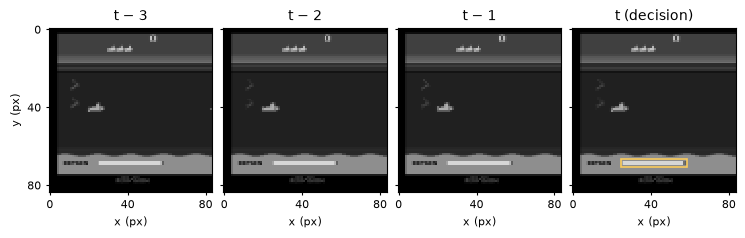

In [2]:
from collections import Counter
from hashlib import sha256
from pathlib import Path
import csv
import json
import logging

import numpy as np

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

pack = work / "runs" / "t03-selection-v1"


def checked_file(path, expected_sha256):
    data = path.read_bytes()
    actual = sha256(data).hexdigest()
    if actual != expected_sha256:
        raise ValueError(f"Evidence digest mismatch for {path}: {actual}")
    return data


summary = json.loads(checked_file(
    pack / "summary.json",
    "90505fbe88f78b11e341efb0c4aec6291cd0149b2884822b29d594fee894b1c1",
))
for filename in ("manifest.csv", "counts.csv", "inputs.npz"):
    checked_file(pack / filename, summary["sha256"][filename])

with (pack / "manifest.csv").open(newline="") as stream:
    manifest = list(csv.DictReader(stream))
with (pack / "counts.csv").open(newline="") as stream:
    counts = list(csv.DictReader(stream))
with np.load(pack / "inputs.npz", allow_pickle=False) as archive:
    stacks, q, actions = (archive[key] for key in ("stacks", "q", "actions"))

games = summary["games"]
assert len(games) == 10 and len(counts) == 40
assert all(game["terminated"] and not game["truncated"] for game in games)
assert sum(game["decision_steps"] for game in games) == 23693
assert len(manifest) == summary["selected"] == 120
assert stacks.shape == (120, 4, 84, 84) and stacks.dtype == np.uint8
assert q.shape == (120, 18) and np.isfinite(q).all()
assert np.array_equal(actions, q.argmax(axis=1))
assert np.array_equal(actions, [int(row["action"]) for row in manifest])
assert [int(row["row_index"]) for row in manifest] == list(range(120))
stack_hashes = [sha256(stack.tobytes()).hexdigest() for stack in stacks]
assert stack_hashes == [row["stack_sha256"] for row in manifest]
assert len(set(stack_hashes)) == summary["duplicates"]["selected"]["distinct_stacks"] == 119
quotas = Counter((row["game_id"], row["stratum"]) for row in manifest)
assert len(quotas) == 30 and set(quotas.values()) == {4}
assert all(quotas[row["game_id"], row["stratum"]] == int(row["selected"]) for row in counts)
gaps = [
    min(np.diff(sorted(int(row["decision_step"]) for row in manifest if row["game_id"] == game["game_id"])))
    for game in games
]
assert min(gaps) == 31
row = manifest[0]
assert (row["sample_id"], int(row["oxygen"]), int(actions[0])) == ("g1000-d56", 60, 0)

fig, axes = plt.subplots(1, 4, figsize=(7.4, 2.12), sharex=True, sharey=True)
for axis, frame, title in zip(axes, stacks[0], ("t − 3", "t − 2", "t − 1", "t (decision)")):
    axis.imshow(frame, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    axis.set_title(title, fontsize=10)
    axis.set_xticks([0, 40, 80])
    axis.set_yticks([0, 40, 80])
    axis.tick_params(labelsize=8, length=2)
    axis.set_xlabel("x (px)", fontsize=8)
axes[0].set_ylabel("y (px)", fontsize=8)
axes[-1].add_patch(Rectangle((24.5, 66.5), 34, 4, fill=False, edgecolor="#f9cb5c", linewidth=1.2))
fig.tight_layout(pad=0.45)
plt.show()

## Explanation methods

Let $a$ be the greedy action on the original stack and $b$ its original runner-up. IG and occlusion use the fixed contrast $Q(a)-Q(b)$ so the question remains the same across perturbations.

**Integrated Gradients (IG).** Integrated Gradients attributes the change from a baseline input to an observed input along a straight path [4]. Using Captum [5], we integrate gradients of the fixed-action contrast from a blurred observation to the original stack and sum signed attributions across frames. The completeness residual compares the attribution sum with the target difference. It measures integration error, while the perturbation benchmark evaluates the resulting ranking.

**Contrastive patch occlusion.** The score is the drop in the same contrast when one patch is replaced with its blurred version across all four frames. Positive values indicate that patch replacement reduced support for $a$ relative to $b$. A patch intervention measures a finite local change and its score depends on patch size, blur and the underlying observation. The course introduced IG in Lecture 6a and occlusion in Tutorial 7.

**Specific and Relevant Feature Attribution (SARFA).** We combine the clipped drop in the original action's softmax-transformed Q score with a specificity term that discounts redistribution among the other actions. The specific effect is useful for a decision with several plausible alternatives. The DQN's action remains a greedy choice and the transform is part of the attribution formula. We implemented the SARFA formulation of Puri et al. [6] with temperature 1 on the same grid as the other methods. We selected SARFA as the method beyond the course materials.

## RQ1. Faithfulness protocol

We fixed the comparison protocol before the full run (commit `fec895d`). All three methods generate maps using per-frame Gaussian blur (sigma 5) and rank the same 196 nonoverlapping 6 × 6 cells by descending signed mean. Exactly equal values use row-major order. IG uses Gauss-Legendre integration with 64, 256, 1,024 or 4,096 steps and tolerance max($10^{-4}$, 2% of the absolute target difference). Occlusion and SARFA share their patch predictions.

Huber et al. used insertion curves to benchmark saliency maps for Atari agents [7]. We evaluate both deletion and insertion. Deletion replaces cells in order. Insertion starts from the filled stack and restores cells in order. Black and blur are evaluated separately at 29 fractions of cells, synchronously across the four frames. For the fixed original action $a$, $M=Q(a)-\max_{j\ne a} Q(j)$ updates the strongest other action, while $C=Q(a)-\mathrm{mean}_j\,Q(j)$ subtracts the mean of all 18 actions. AUC integrates either score along the fraction of cells replaced or restored. Lower deletion and higher insertion AUC are favorable. The flip rate is the fraction of evaluated progress points where the greedy action differs from $a$.

Five seeded random orders are averaged within each state. State metrics are averaged within a game, then games are weighted equally. The paired game bootstrap uses 20,000 draws and Bonferroni-adjusted percentile intervals across 24 method-pair/fill/direction/metric comparisons. The sensitivity check resamples the four overlap families and also leaves each family out in turn. A method dominates another only if the favorable lower bound is above zero on all eight criteria in both bootstrap schemes. Remaining candidates stay tied under this rule.

## RQ1. Results on the selection games

**Answer.** The benchmark retained IG, occlusion and SARFA because no method met the declared dominance rule against another. The preferred method varies with the fill, perturbation direction and score. Ten game IDs represent four highly overlapping trajectory families, which limits the meaning of the paired intervals.

**Table 2. Selection-set AUCs.** Ten equally weighted game means, from 120 selected states. $M$ is fixed-action margin, $C$ is centered Q, and AUCs are in Q-value units over cell fractions from 0 to 1. Deletion favors smaller values. Insertion favors larger values.

| Fill | Order | Deletion $M$ | Insertion $M$ | Deletion $C$ | Insertion $C$ |
| --- | --- | ---: | ---: | ---: | ---: |
| Black | IG | −0.31724 | −0.35236 | 0.01819 | −0.00324 |
| Black | Occlusion | −0.24330 | −0.26878 | 0.02593 | 0.01540 |
| Black | SARFA | −0.23071 | −0.32374 | −0.00647 | 0.02881 |
| Black | Random | −0.23437 | −0.22730 | 0.01663 | 0.02252 |
| Blur | IG | −0.14799 | −0.04683 | −0.01217 | 0.08398 |
| Blur | Occlusion | −0.12092 | −0.04073 | 0.00312 | 0.10801 |
| Blur | SARFA | −0.09025 | −0.01662 | −0.00387 | 0.17372 |
| Blur | Random | −0.06088 | −0.06034 | 0.03877 | 0.03958 |

IG has the lowest deletion margin AUC with either fill. SARFA has the highest blur insertion AUC for both scores and the lowest black deletion centered AUC. Against the paired random baseline, margin AUC favored random for all three methods on black insertion on average, while all three averaged above random on blur insertion. IG’s black insertion difference was −0.1251 (95% paired interval −0.1754 to −0.0823). SARFA’s blur insertion difference was 0.0437 (0.0295 to 0.0565). These intervals are descriptive. Blur insertion flips occur at 70.40%, 66.67%, 49.45% and 79.56% of evaluated points for IG, occlusion, SARFA and random, respectively. These percentages describe the perturbation path.

**Numerical checks.** All 120 original actions matched the saved selection actions, and all 3,840 paths passed full-Q endpoint checks. Maximum original Q difference was $1.91 \times 10^{-6}$. IG met the completeness criterion on 117/120 original states. The three failures at 4,096 steps (`g1003-d2115`, `g1008-d1890`, `g1009-d171`) remained in the comparison. All 120 randomized-model IG runs met tolerance. QIAN's independent review replayed 2,004,480 curve Q-values and 423,360 single-patch Q-values. Curve Q-values agreed to $2.86 \times 10^{-6}$ and derived metrics matched exactly.

**Randomization and cost.** The corrected mean cosines between the trained and final-layer-reset models' 196 signed cell means were −0.00736, −0.00621 and 0.39373 for IG, occlusion and SARFA. SARFA retained appreciable structure under this check. All cosines were defined and the original model digest stayed fixed. The study run took 1,043.82 s. Mean per-state map times were 5.792 s for IG and 0.139 s each for the two methods that share patch predictions.

## RQ1. Deletion and insertion curves

**Figure 2.** Policy-score curves for 120 selection states from ten equally weighted games. Fraction is the 0–1 share of jointly replaced (deletion) or restored (insertion) cells, from 29 evaluated points. Each random curve averages five orders per state. The bundle contains compact score paths derived from the reviewed selection Q-vectors for these curves and Table 2. Axis units are Q-values.

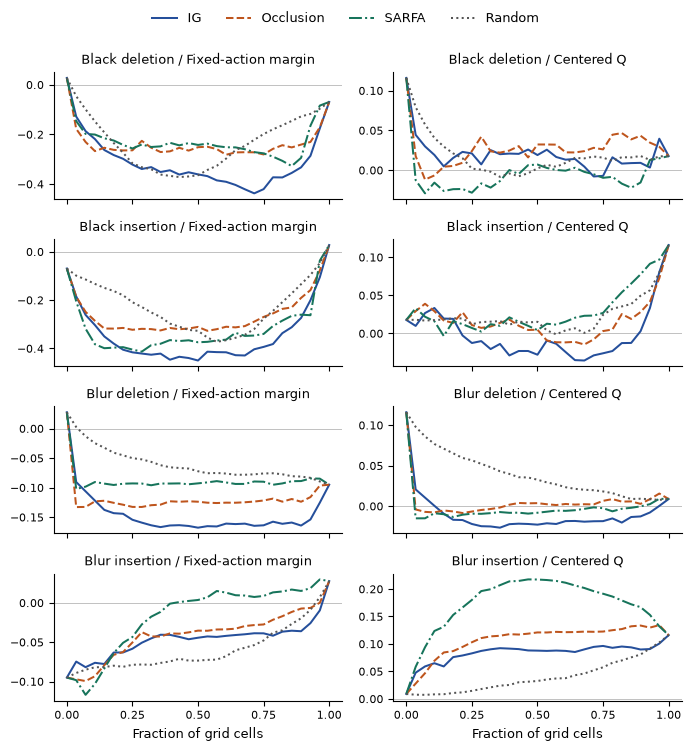

In [3]:
from io import StringIO

review_dir = work / "integration" / "seaquest_study" / "evidence" / "t06-review"
accepted = json.loads(checked_file(
    review_dir / "accepted.json",
    "3ab6676ffe8009d986f9139633b915018a8b85fbf6fbe904cf35951e01fe9106",
))
receipt = json.loads(checked_file(
    review_dir / "receipt.json",
    "16902338cab7d6f8487f45ae818e8a6e63b4435a3785d9f844a4c8d4795575c6",
))
assert accepted["status"] == "accepted" and accepted["selection_commit"] == receipt["reviewed_pr_head"]
assert accepted["selection_summary_sha256"] == sha256((pack / "summary.json").read_bytes()).hexdigest()
assert accepted["checkpoint_sha256"] == summary["checkpoint_sha256"]
protocol = json.loads(checked_file(review_dir / "protocol.json", accepted["protocol_sha256"]))

selection_run = work / "t06-review" / "issue 6" / "results"
t06 = json.loads(checked_file(selection_run / "report.json", receipt["input_sha256"]["report.json"]))
digest = receipt["input_sha256"]["evidence.npz"]
assert digest == t06["output_sha256"]["evidence.npz"]
score_file = selection_run / "curve_scores.npz"
checked_file(score_file, "9d9d3ef97be12eab6fb8079f4a8a4dfa00529ee401773aea36948e34fdf8aa0a")
with np.load(score_file, allow_pickle=False) as archive:
    assert archive["source_evidence_sha256"].item() == digest
    scores = [archive["margin"], archive["centered"]]
assert all(path.shape == (120, 8, 2, 2, 29) for path in scores)

comparison = checked_file(selection_run / "comparison.csv", t06["output_sha256"]["comparison.csv"])
comparison_rows = {
    (r["method"], r["fill"], r["direction"]): r
    for r in csv.DictReader(StringIO(comparison.decode()))
}
signed_cosines = checked_file(
    review_dir / "randomization-cell-summary.csv",
    accepted["review_tables_sha256"]["randomization-cell-summary.csv"],
)
means = [round(float(row["mean"]), 5) for row in csv.DictReader(StringIO(signed_cosines.decode()))]
assert means == [-0.00736, -0.00621, 0.39373]
paired = checked_file(
    review_dir / "random-baseline-paired.csv",
    accepted["review_tables_sha256"]["random-baseline-paired.csv"],
)
assert len(list(csv.DictReader(StringIO(paired.decode())))) == 24

fractions = np.array(protocol["counts"]) / 196
game_rows = np.array([row["game_id"] for row in manifest])
ordered_games = sorted(set(game_rows))
methods = [*protocol["methods"], "random"]
colors = ["#254f9b", "#be551d", "#17745b", "#555555"]
styles = ["-", "--", "-.", ":"]
labels = ["IG", "Occlusion", "SARFA", "Random"]
fig, axes = plt.subplots(4, 2, figsize=(7.1, 7.6), sharex=True)
for fi, fill in enumerate(protocol["fills"]):
    for di, direction in enumerate(protocol["directions"]):
        for metric_index, metric in enumerate(("margin_auc", "centered_auc")):
            axis = axes[fi * 2 + di, metric_index]
            values = scores[metric_index][:, :, fi, di]
            for mi, method in enumerate(methods):
                states = values[:, mi] if mi < 3 else values[:, 3:].mean(axis=1)
                means = np.stack([states[game_rows == game].mean(axis=0) for game in ordered_games])
                curve = means.mean(axis=0)
                expected = float(comparison_rows[method, fill, direction][metric])
                assert np.isclose(np.trapezoid(curve, fractions), expected, rtol=0, atol=3e-7)
                axis.plot(fractions, curve, color=colors[mi], ls=styles[mi], label=labels[mi], lw=1.45)
            metric_label = ("Fixed-action margin", "Centered Q")[metric_index]
            axis.set_title(f"{fill.title()} {direction} / {metric_label}", fontsize=9)
            axis.axhline(0, color="#a8a8a8", linewidth=0.5, zorder=0)
            axis.set_ylim(auto=True)
            axis.tick_params(labelsize=8)
            axis.spines[["top", "right"]].set_visible(False)
            axis.set_xticks([0, 0.25, 0.5, 0.75, 1])
for axis in axes[-1]:
    axis.set_xlabel("Fraction of grid cells", fontsize=9)
handles, names = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, names, loc="upper center", ncol=4, fontsize=9, frameon=False)
fig.tight_layout(rect=(0.01, 0.01, 1, 0.955), h_pad=1.15)
plt.show()

## RQ1. Agreement and disagreement in example states

Among the 120 selection decisions, we identified the highest and lowest cosine similarity between the IG and occlusion maps on the common grid. The two examples illustrate extreme agreement and disagreement and are outside the ranking rule.

- **Agreement, `g1008-d2101`.** The original action is 1 and runner-up is 3. The cosine is 0.758 and all three methods put cell 116 first. Blurring that cell lowers the fixed-pair contrast by 0.145175 Q units.
- **Disagreement, `g1007-d1582`.** The original action is 5 and runner-up is 9. The cosine is −0.196. IG puts cell 88 first, and blurring it increases the contrast by 0.020188 Q units. Occlusion and SARFA put cell 9 first, where blurring lowers the contrast by 0.027797 Q units.

An integrated path contribution and a finite patch replacement can differ in sign. SARFA also scores relative support across action alternatives [6], so its agreement with a fixed-pair ranking depends on the input.

## Held-out collection and isolation audit

All 20 games assigned to the held-out split reached game over, yielding 46,186 decisions and 80 life losses. Before sampling, we compared each candidate’s four-frame input with every input in the raw selection trajectories and removed exact matches. Checking only the 120 sampled selection states would have flagged three provisional held-out rows. All 300 provisional rows matched the larger raw selection pool.

**Table 3. Held-out coverage after exact stack exclusion.** The history-filtered counts precede duplicate exclusion. Five rows per game and stratum were planned.

| Oxygen stratum | History eligible | Exact selection matches removed | Retained / target | Games contributing |
| --- | ---: | ---: | ---: | ---: |
| Low (1-15) | 7,456 | 7,456 | 0 / 100 | 0 / 20 |
| Medium (16-44) | 19,050 | 19,050 | 0 / 100 | 0 / 20 |
| High (45-64) | 15,947 | 15,947 | 0 / 100 | 0 / 20 |
| **Total** | **42,453** | **42,453** | **0 / 300** | **0 / 20** |

The raw partitions share 9,112 distinct stacks. All 36 unmatched held-out records occur at decisions 0-2 and contain reset padding. Thirty game IDs produced 20 distinct full ordered stack sequences. Several whole sequences match across the split, including `g1000/g1026` and `g1001/g1015/g1019`. This dependence is a limitation of the seed split under this deterministic protocol.

In [4]:
qc_dir = work / "integration" / "seaquest_study" / "evidence" / "t07"
qc = json.loads(checked_file(
    qc_dir / "summary.json",
    "bf01f27fcbeb4c5c7254832fef252539c93aae617674a82a3ccee4c31c75ca13",
))
assert qc["selection_summary_sha256"] == accepted["selection_summary_sha256"]
qc_counts = checked_file(qc_dir / "counts.csv", qc["sha256"]["counts.csv"])
qc_rows = list(csv.DictReader(StringIO(qc_counts.decode())))
assert len(qc_rows) == 80
by_stratum = {
    stratum: sum(int(row["candidates"]) for row in qc_rows if row["stratum"] == stratum)
    for stratum in ("low", "medium", "high")
}
assert tuple(by_stratum.values()) == (7456, 19050, 15947)
assert sum(by_stratum.values()) == qc["eligible"] == 42453
assert all(int(row["selection_raw_duplicate"]) == int(row["candidates"]) for row in qc_rows)
assert sum(int(row["selected"]) for row in qc_rows) == qc["selected"] == 0
assert qc["shortfall"] == qc["target"] == 300
event_index = checked_file(qc_dir / "events.csv", qc["sha256"]["events.csv"])
windows = list(csv.DictReader(StringIO(event_index.decode())))
assert len(windows) == qc["events"]["indexed"] == 80
assert all(row["status"] == "conflict" and int(row["raw_conflict_steps"]) == 30 for row in windows)
print("T07 isolation QC: 42,453 eligible; 0/300 signed; 80/80 event windows overlapped.")

T07 isolation QC: 42,453 eligible; 0/300 signed; 80/80 event windows overlapped.


## RQ2. Oxygen-gauge reliance

**Original environment (sticky-action probability 0).** We could not estimate how gauge reliance varied across oxygen strata. All 42,453 decisions that passed the history filter matched the raw selection trajectories. None of the 20 games contributed an isolated input toward the target of 300. With no eligible observations in any stratum, we could estimate neither effects nor intervals.

The analysis protocol specifies four disjoint 136-pixel regions per policy frame. All use $25 \le x < 59$. The full gauge includes depleted space at $67 \le y < 71$. The neighboring HUD, score and playfield use $72 \le y < 76$, $3 \le y < 7$ and $40 \le y < 44$. Candidate geometry varied during setup. The accepted HUD control had only three patch patterns across the 480 selection frames, which limits what its contrast represents.

For each retained method, record the mean positive attribution per pixel in native units by region and its share of total positive attribution (undefined when the denominator is zero). Black and blur separately replace the region on all four frames. Record before-minus-after fixed-action margin, centered action value and upward preference, plus action flips. Upward preference is the maximum Q of actions 2, 6, 7, 10, 14 and 15 minus the maximum Q of other actions. Estimate paired gauge-minus-control effects by oxygen stratum with within-game averaging, equal game weights and 20,000 game-bootstrap draws. Report game and state counts and describe original margin, depth and collected-diver context. Actual oxygen and game dynamics stay fixed during the pixel test. With all 60 game-stratum cells empty, the formal run performed no interventions or attribution calculations. Its aggregate and per-game tables keep estimates and 95% intervals blank. This is a coverage result.

**Figure 3. Coverage in the original held-out games.** The figure shows the number of decisions remaining after exclusion and the number of games they represent. With no retained decisions, the effect tables have no estimates for any method or fill.

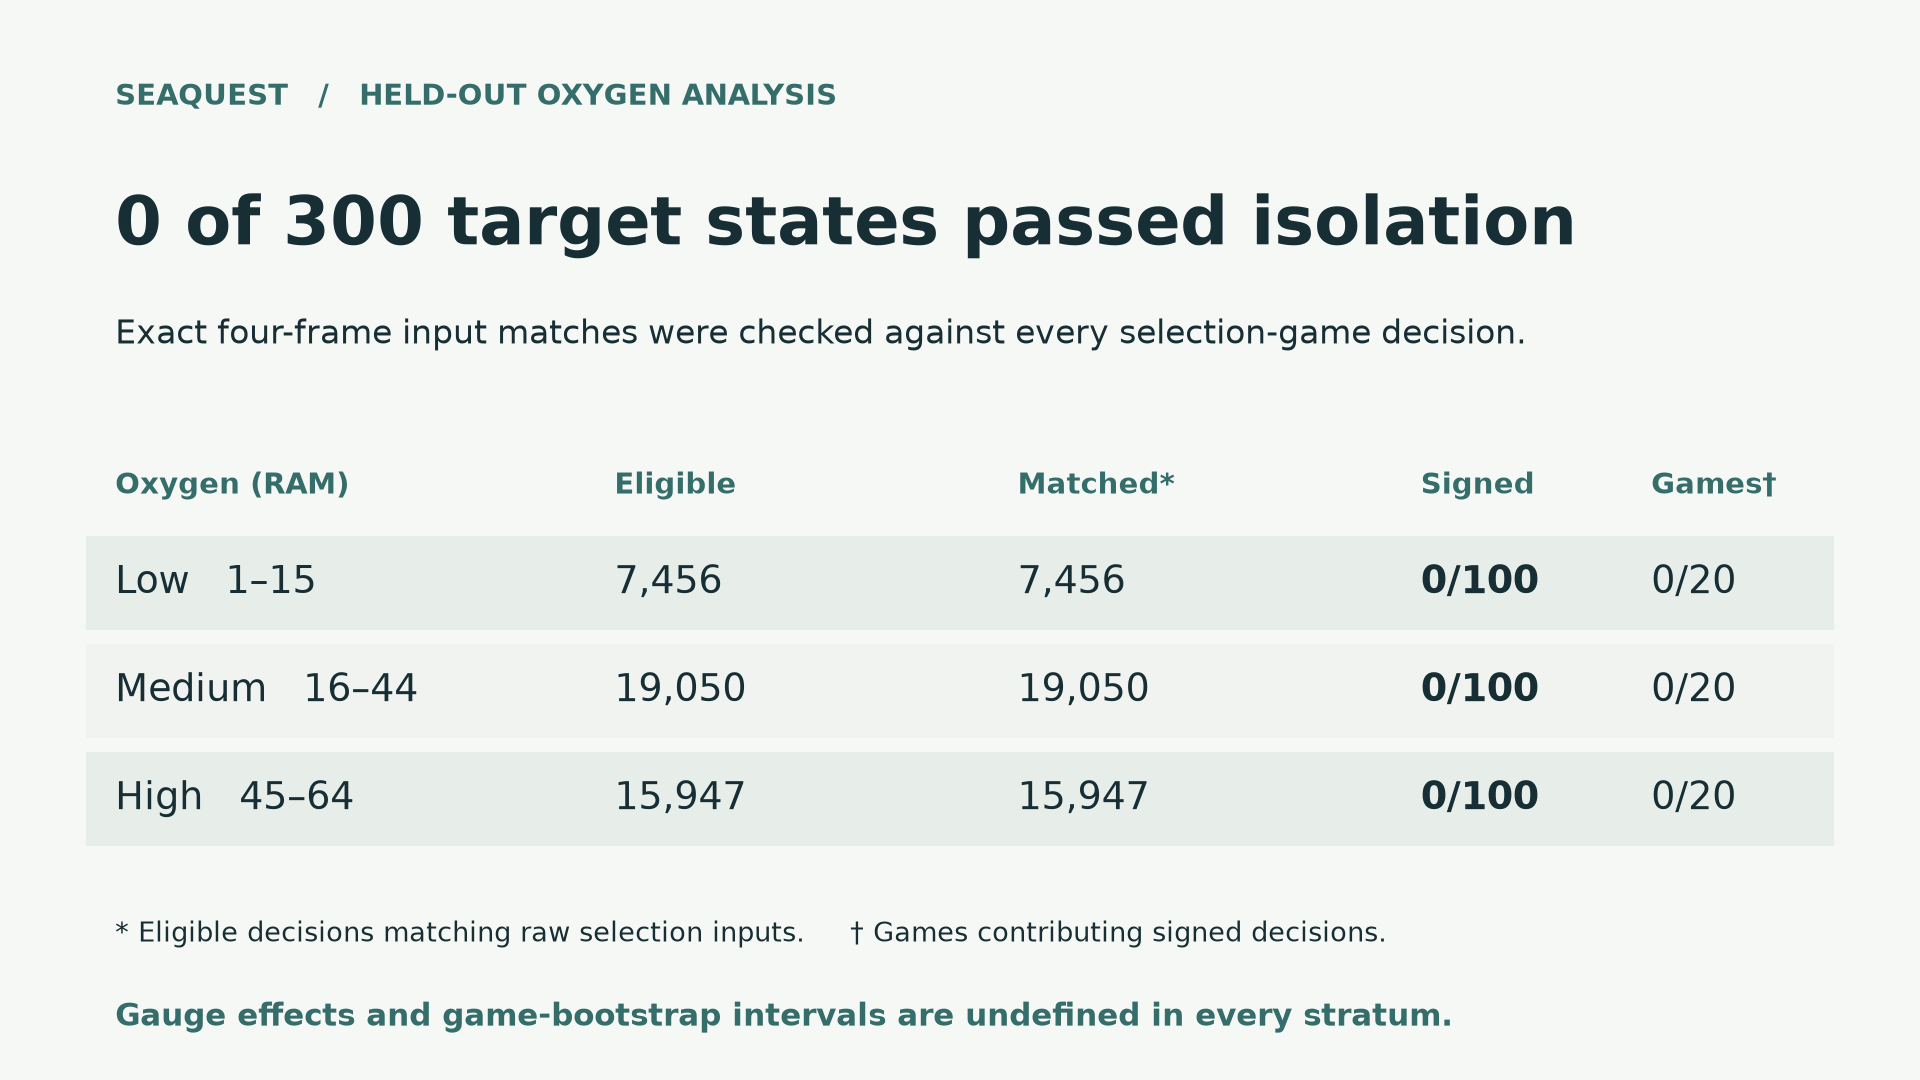

In [5]:
from IPython.display import Image, display

signed_dir = work / "runs" / "t08-oxygen-v1"
signed = json.loads(checked_file(
    signed_dir / "summary.json",
    "81ec0c26f7c10ccdc7be105008e5b34a346f5381fde968f5c5b6d807cf37feea",
))
assert signed["accepted_sha256"] == sha256((review_dir / "accepted.json").read_bytes()).hexdigest()
assert signed["input"]["qc_summary_sha256"] == sha256((qc_dir / "summary.json").read_bytes()).hexdigest()
assert signed["scope"] == "signed_heldout"
assert signed["states"] == signed["contributing_games"] == signed["effect_estimates_defined"] == 0
assert signed["eligible"] == signed["selection_raw_duplicates"] == qc["eligible"]
assert signed["target"] == 300 and signed["missing_game_strata"] == 60
coverage = checked_file(signed_dir / "coverage.csv", signed["output_sha256"]["coverage.csv"])
coverage_rows = list(csv.DictReader(StringIO(coverage.decode())))
assert [int(row["eligible"]) for row in coverage_rows] == [7456, 19050, 15947, 42453]
assert all(row["signed_states"] == row["games_contributing"] == "0" for row in coverage_rows)

for name in ("estimates.csv", "game_estimates.csv"):
    table = checked_file(signed_dir / name, signed["output_sha256"][name])
    rows = list(csv.DictReader(StringIO(table.decode())))
    assert len(rows) == {"estimates.csv": 412, "game_estimates.csv": 8240}[name]
    assert all(row["states"] == "0" and row["estimate"] == "" for row in rows)
    assert all(row.get("lo95", "") == row.get("hi95", "") == "" for row in rows)

cover_plot = checked_file(signed_dir / "coverage.png", signed["output_sha256"]["coverage.png"])
display(Image(data=cover_plot, width=720))

## RQ2. A held-out cohort with sticky actions

ALE repeated the previous action with probability 0.25 per emulator frame. The frozen methods, thresholds and 30-decision spacing stayed fixed. From 42,842 decisions across seeds 5200–5219, we selected 300 distinct inputs after excluding 3,725 history-ineligible decisions and 237 further decisions seen in the original 30 games or three pilots. Each new game contributed five decisions per oxygen stratum (100 per stratum). The longest continuous trajectory overlap was 2.15% of the shorter game.

**Attribution and intervention.** The three method columns give the percentage of each method’s total positive attribution inside the gauge, averaged within game and then across 20 games. All 900 gauge shares had positive denominators. The means retain the 12 IG decisions that reached the step limit without meeting tolerance. The final columns give the paired gauge-minus-HUD difference in fixed-action margin drop (Q units), with descriptive 95% intervals from 20,000 whole-game bootstrap draws.


In [6]:
# Recompute the sticky-action panel from the frozen inputs and paired game tables.
sticky = work / "sticky"
def sticky_rows(name):
    with (sticky / name).open(newline="") as source:
        return list(csv.DictReader(source))

design = json.loads((sticky / "protocol.json").read_text())
coverage = json.loads((sticky / "coverage.json").read_text())
measurement = json.loads((sticky / "measurement.json").read_text())
receipt = json.loads((sticky / "verification.json").read_text())
assert design["repeat_action_probability"] == 0.25
assert measurement["bootstrap"] == {"unit":"game", "seed":5495, "repetitions":20000, "percentiles":[2.5,97.5]}
assert set(design["pilot_seeds"]).isdisjoint(design["cohort_seeds"])
assert coverage["original_decisions"] == 69879 and coverage["pilot_decisions_excluded"] == 7521
assert (coverage["selected"], coverage["target"], len(coverage["games"])) == (300, 300, 20)
assert coverage["by_stratum"] == {"low": 100, "medium": 100, "high": 100}
assert len(measurement["ig_nonconverged"]) == 12 and len(measurement["families"]) == 20
assert (measurement["states"],measurement["interventions"],measurement["attributions"]) == (300,2400,3600)
selected = sticky_rows("selected.csv")
checked_file(sticky / "selected.csv", coverage["sha256"]["selected.csv"])
checked_file(sticky / "samples.npz", receipt["samples_sha256"])
with np.load(sticky / "samples.npz", allow_pickle=False) as samples:
    hashes = [sha256(stack.tobytes()).hexdigest() for stack in samples["stacks"]]
    assert len(set(hashes)) == 300 and set(hashes).isdisjoint(stack_hashes)
    assert hashes == [row["stack_sha256"] for row in selected]
    assert samples["q_values"].shape == (300, 18)
    np.testing.assert_array_equal(samples["q_values"].argmax(axis=1), samples["action"])
prior_bytes = (sticky / "prior-input-digests.bin").read_bytes()
assert len(prior_bytes) % 32 == 0
prior_digests = {prior_bytes[i:i+32].hex() for i in range(0, len(prior_bytes), 32)}
assert prior_digests.isdisjoint(hashes)
assert set(Counter((r["game_id"], r["stratum"]) for r in selected).values()) == {5}
by_stratum_game = {(r["stratum"], r["game_id"]): r for r in sticky_rows("game_margin_contrasts.csv")}
game_ids = sorted({r["game_id"] for r in selected})
draws = np.random.default_rng(5495).integers(20, size=(20000, 20))
panel = sticky_rows("figure_source.csv")
checked_file(sticky / "figure_source.csv", measurement["sha256"]["figure_source.csv"])
assert len(panel) == 18 and len(by_stratum_game) == 60
for row in panel:
    key = f"{row['fill']}_oxygen_minus_{row['control']}"
    values = np.array([float(by_stratum_game[row["stratum"], game][key]) for game in game_ids])
    limits = np.quantile(values[draws].mean(axis=1), [.025, .975])
    np.testing.assert_allclose([values.mean(), *limits], [float(row[k]) for k in ("estimate","lo95","hi95")], rtol=0, atol=1e-10)
peer = json.loads((sticky / "independent-summary.json").read_text())
assert peer["unique_new"] == peer["greedy_matches"] == 300
assert peer["interventions"] == 2400 and peer["max_original_q_error"] <= 1.91e-6
assert peer["max_estimate_or_ci_error"] <= 4.52e-7 and peer["plot_changed_pixels"] == 0

# Compare the same 300 decisions under all three explanation methods and both fills.
from collections import defaultdict
from IPython.display import Markdown

methods = ("ig", "occlusion", "sarfa")
strata = ("low", "medium", "high")
peer_receipt = json.loads((sticky / "full-verification.json").read_text())
state_lookup = {row["stack_sha256"]: row for row in selected}
records = sticky_rows("gauge-observations.csv")
assert len(records) == len({r["stack_sha256"] for r in records}) == len(state_lookup) == 300

shares = defaultdict(list)
drops = defaultdict(list)
undefined = Counter()
ig_failed = set()
for row in records:
    sample = state_lookup[row["stack_sha256"]]
    game, stratum = sample["game_id"], sample["stratum"]
    if row["ig_converged"] == "False":
        ig_failed.add(f"{game}-d{sample['decision_step']}")
    for method in methods:
        value = row[f"{method}_fraction"]
        if row[f"{method}_zero_total_positive"] == "1":
            assert value == ""
            undefined[method] += 1
            continue
        fraction = float(value)
        assert np.isfinite(fraction) and 0 <= fraction <= 1
        shares[game, stratum, method].append(fraction)
    for fill in ("black", "blur"):
        for region in ("oxygen", "neighboring_hud"):
            value = float(row[f"{fill}_{region}_drop"])
            assert np.isfinite(value)
            drops[game, stratum, fill, region].append(value)
assert ig_failed == set(peer_receipt["ig_fails_sorted"]) == set(measurement["ig_nonconverged"])
assert [undefined[m] for m in methods] == [0, 0, 0]
assert all(len(values) == 5 for values in (*shares.values(), *drops.values()))

def equal_game_mean(groups, *key):
    return np.mean([np.mean(groups[(game, *key)]) for game in game_ids])

hud_panel = {(r["stratum"], r["fill"]): r for r in panel if r["control"] == "neighboring_hud"}
table = ["| Oxygen | IG % | Occlusion % | SARFA % | Black [95% interval] | Blur [95% interval] |",
         "| --- | ---: | ---: | ---: | ---: | ---: |"]
for stratum in strata:
    entries = [stratum.capitalize()]
    for method in methods:
        share = equal_game_mean(shares, stratum, method)
        np.testing.assert_allclose(share, peer_receipt["attribution_gauge_fraction_means"][f"{stratum}/{method}"])
        entries.append(f"{share * 100:.2f}")
    for fill in ("black", "blur"):
        result = hud_panel[stratum, fill]
        contrast = (equal_game_mean(drops, stratum, fill, "oxygen")
                    - equal_game_mean(drops, stratum, fill, "neighboring_hud"))
        np.testing.assert_allclose(contrast, float(result["estimate"]), atol=5e-7, rtol=0)
        entries.append(f"{contrast:+.3f} [{float(result['lo95']):+.3f}, {float(result['hi95']):+.3f}]")
    table.append("| " + " | ".join(entries) + " |")
# Natural column widths keep each reported interval together in the PDF.
latex_rows = [line.strip("|").split("|") for i, line in enumerate(table) if i != 1]
latex_table = [r"\begin{center}\small\begin{tabular}{@{}lrrrrr@{}}\toprule"]
for i, row in enumerate(latex_rows):
    latex_table.append(" & ".join(v.strip().replace("%", r"\%") for v in row) + r" \\")
    if i == 0:
        latex_table.append(r"\midrule")
latex_table.append(r"\bottomrule\end{tabular}\end{center}")
display({"text/markdown": "\n".join(table), "text/latex": "\n".join(latex_table)}, raw=True)

for region, expected in (("oxygen", [0.140, 0.073, 0.085]), ("neighboring_hud", [0.526, 0.887, 1.210])):
    observed = [equal_game_mean(drops, s, "black", region) for s in strata]
    np.testing.assert_allclose(observed, expected, rtol=0, atol=.0005)

| Oxygen | IG % | Occlusion % | SARFA % | Black [95% interval] | Blur [95% interval] |
| --- | ---: | ---: | ---: | ---: | ---: |
| Low | 6.59 | 6.28 | 8.00 | -0.386 [-0.449, -0.323] | +0.037 [+0.013, +0.060] |
| Medium | 9.40 | 8.57 | 8.85 | -0.814 [-0.951, -0.692] | +0.039 [+0.028, +0.051] |
| High | 12.52 | 8.89 | 11.61 | -1.125 [-1.238, -1.015] | +0.042 [+0.024, +0.063] |

**Figure 3b. Gauge and HUD pixel interventions in the new cohort.** Both panels share a horizontal Q scale. From low to high oxygen, all three maps assigned a growing share to the gauge. Blackening the gauge alone produced a nonmonotonic margin drop (0.140, 0.073, 0.085 Q). Blackening the HUD produced a growing drop (0.526, 0.887, 1.210 Q), driving the widening negative contrast. Blurring the gauge reduced the margin more than blurring the HUD in all three strata. Greater attribution concentration therefore did not consistently track greater sensitivity to gauge replacement.

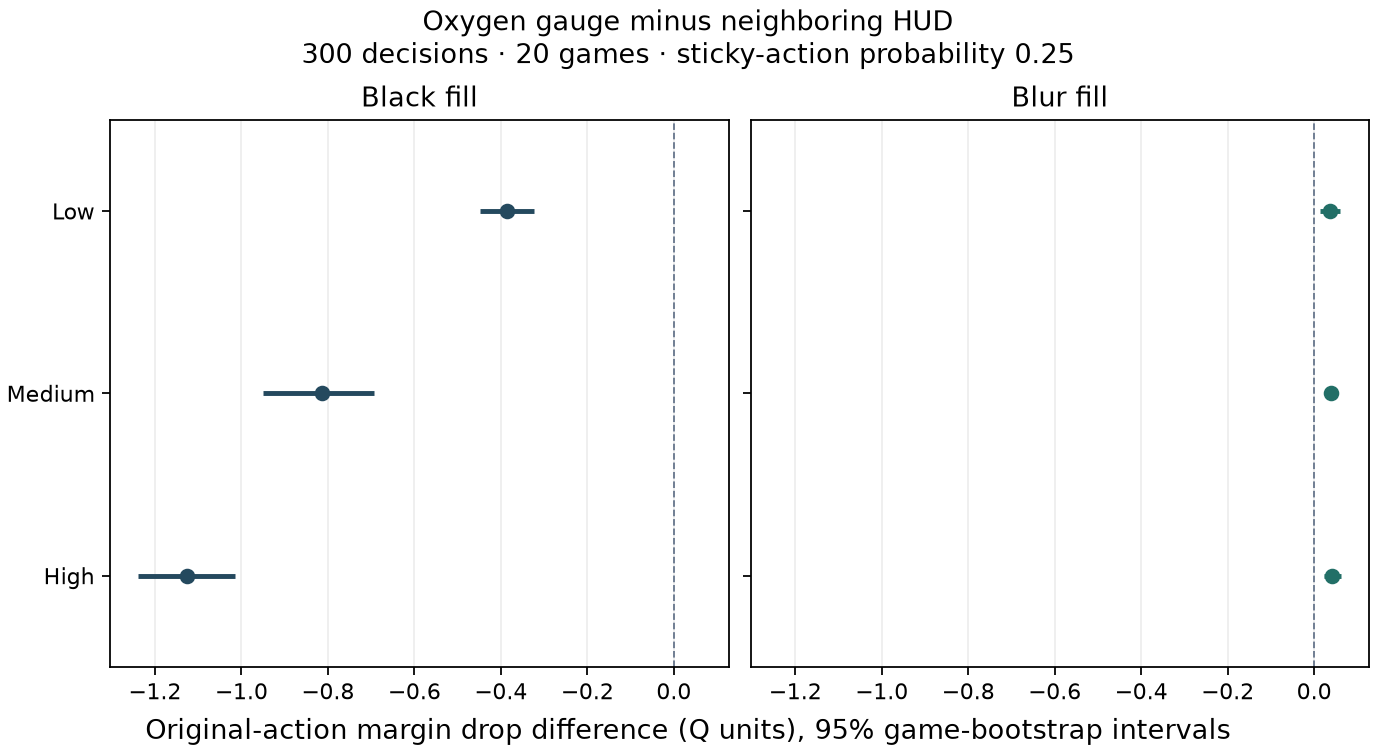

In [7]:
figure = checked_file(sticky / "margin_contrasts.png", measurement["sha256"]["margin_contrasts.png"])
display(Image(data=figure, width=720))

## RQ2. State context and action changes

**Before replacing pixels.** These profiles describe the same 300 sticky-action decisions as Figure 3b. High-oxygen states had a lower mean raw depth reading, fewer collected divers and a lower proportion of upward actions than the other strata. The original action margins were small in all three groups. A change of top action can therefore accompany a small change in Q. Each table gives equal weight to the 20 games.

In [8]:
# Recover each displayed mean and its paired interval from its 20 game estimates.
metrics = ("stratum", "method", "fill", "metric", "region", "control")
per_game = defaultdict(dict)
for row in sticky_rows("replay-game-estimates.csv"):
    key = tuple(row[k] for k in metrics)
    assert row["game_id"] not in per_game[key]
    per_game[key][row["game_id"]] = row
reference = {tuple(row[k] for k in metrics): row for row in sticky_rows("replay-estimates.csv")}

def profile(stratum, metric, fill="", region="", method="", control=""):
    key = (stratum, method, fill, metric, region, control)
    baseline = reference[key]
    assert (int(baseline["states"]), int(baseline["games"]), int(baseline["missing_games"])) == (100, 20, 0)
    assert set(per_game[key]) == set(game_ids) and all(int(r["states"]) == 5 for r in per_game[key].values())
    values = np.array([float(per_game[key][g]["estimate"]) for g in game_ids])
    assert np.isfinite(values).all()
    summary = (values.mean(), *np.quantile(values[draws].mean(axis=1), [.025, .975]))
    np.testing.assert_allclose(summary, [float(baseline[k]) for k in ("estimate", "lo95", "hi95")], atol=1e-10)
    return summary

context_rows = ["| Oxygen | Depth (RAM 97) | Collected divers | Original margin (Q) | UP chosen |",
                "| --- | ---: | ---: | ---: | ---: |"]
action_rows = ["| Oxygen | Fill | Action flipped | UP preference drop, Q [95% interval] |",
               "| --- | --- | ---: | ---: |"]
for s in strata:
    depth, divers, margin, up_rate = [profile(s, field)[0] for field in
                                      ("depth", "divers", "original_margin", "original_up_action")]
    context_rows.append(f"| {s.capitalize()} | {depth:.2f} | {divers:.2f} | {margin:.4f} | {up_rate:.0%} |")
    for fill in ("black", "blur"):
        flips = profile(s, "flip", fill, "oxygen")[0]
        up, low, high = profile(s, "up_preference_drop", fill, "oxygen")
        action_rows.append(f"| {s.capitalize()} | {fill.capitalize()} | {flips:.0%} | {up:+.3f} [{low:+.3f}, {high:+.3f}] |")
    for method in methods:
        mean, low, high = profile(s, "positive_density", region="oxygen", method=method, control="neighboring_hud")
        if s!='low' or method=='sarfa':
            assert low > 0
        elif method == 'ig':
            assert high < 0
        else:
            assert low < 0 < high
display(Markdown("\n".join(context_rows)))
display(Markdown("**Replacing the oxygen gauge.** Each flip rate uses the same 100 decisions per stratum. "
                 "UP preference is the best upward-action Q value minus the best value among all other actions. "
                 "The drop is the original preference minus the preference after replacement.\n\n" + "\n".join(action_rows)))


| Oxygen | Depth (RAM 97) | Collected divers | Original margin (Q) | UP chosen |
| --- | ---: | ---: | ---: | ---: |
| Low | 67.08 | 0.64 | 0.0379 | 53% |
| Medium | 67.96 | 0.65 | 0.0195 | 48% |
| High | 58.23 | 0.39 | 0.0233 | 30% |

**Replacing the oxygen gauge.** Each flip rate uses the same 100 decisions per stratum. UP preference is the best upward-action Q value minus the best value among all other actions. The drop is the original preference minus the preference after replacement.

| Oxygen | Fill | Action flipped | UP preference drop, Q [95% interval] |
| --- | --- | ---: | ---: |
| Low | Black | 81% | +0.018 [-0.015, +0.053] |
| Low | Blur | 81% | -0.004 [-0.021, +0.011] |
| Medium | Black | 72% | -0.030 [-0.043, -0.017] |
| Medium | Blur | 83% | -0.016 [-0.026, -0.007] |
| High | Black | 75% | -0.021 [-0.039, -0.002] |
| High | Blur | 86% | -0.056 [-0.078, -0.036] |

At low oxygen, replacing the gauge changed the selected action on 81% of inputs under either fill. Both descriptive 95% intervals for the mean change in UP preference span zero. A flip can switch between two actions that both point upward, or between two that do not. At medium and high oxygen, the negative preference drops indicate that replacement increased relative support for upward actions on average.

**Gauge versus neighboring HUD attribution.** At low oxygen, the 95% game interval for mean gauge-minus-HUD positive attribution density was below zero for IG, crossed zero for occlusion and was above zero for SARFA. All three intervals were above zero at medium and high oxygen. Each comparison uses the method’s own units. The state profiles describe differences among strata, and the interventions changed only input pixels.

## RQ2. Exploratory supplement on revisited observations

**Answer for the revisited cohort.** Replacing the oxygen gauge had different relative effects across fills and controls. Compared with the neighboring HUD, blacking out the gauge produced a smaller original-action margin drop in every oxygen stratum. Blurring the gauge produced a slightly larger drop than blurring that HUD region in every stratum. These exploratory observations were ineligible for the original held-out analysis, which retained 0 of 300 target decisions.

The preregistered supplement starts from the 300 provisional pre-isolation decisions, drops the three that exactly match any of the 120 sampled selection inputs and keeps the original strata, spacing and ID pairs without refilling. The remaining **297 decisions** include **292 distinct four-frame inputs**. All 297 appear in the raw selection trajectories. Twenty game IDs form four overlapping families, using contiguous exact stack overlap of at least 99% of the shorter trajectory as the grouping rule. The estimates describe those revisited decisions.

**Table 4. Gauge minus neighboring HUD.** Entries are mean differences in original-action margin drop in model Q units. Each drop is before minus after replacement. Positive differences indicate stronger support loss from replacing the gauge than the control. Means weight games equally and the brackets show descriptive paired-game 95% percentile intervals. All 20 games contributed to every row.

| Stratum | States | Black mean [95% interval] | Blur mean [95% interval] |
| --- | ---: | ---: | ---: |
| Low | 98 | -0.3632 [-0.4103, -0.3173] | +0.0326 [0.0185, 0.0467] |
| Medium | 99 | -0.8196 [-0.9092, -0.7274] | +0.0489 [0.0273, 0.0747] |
| High | 100 | -1.2895 [-1.4495, -1.1321] | +0.0265 [0.0137, 0.0381] |

The control choice also changes the pattern. With black fill the gauge-minus-score difference was positive in all three strata (0.1292, 0.0649 and 0.0415 Q). The black gauge-minus-playfield difference changed from 0.0923 Q at low oxygen to -0.0394 and -0.0805 Q at medium and high oxygen. All nine blur contrasts ranged from +0.0265 to +0.0740 Q. In 90/297 decisions, all 544 pixel values in the playfield rectangle across four frames were identical. The gauge, neighboring HUD and score rectangles each had 0/297 such decisions. The playfield comparison therefore includes many uniform patches. The neighboring HUD had just three distinct 136-pixel frame patterns.

We drew 20,000 paired bootstrap samples of game means and separately sampled the four whole trajectory families, preserving their games. None of the 18 margin intervals from either approach included zero for this cohort. The intervals describe cross-game means under these resamplings. Repeated input content and just four families limit their use for broader inference.

Across the cohort the three methods yielded 3,564 regional attribution rows. All 2,376 region/fill interventions were independently replayed, with zero flip mismatches and zero errors in the three Q-derived effects. The independent recalculation checked all 18 contrast means and intervals, differing by at most $4.44 \times 10^{-16}$ even when including leave-one-family-out extremes. The 15 original-model IG failures at the step cap were retained and flagged.

## Revisited results by fill and control

**Figure 4. Exploratory margin contrasts, gauge minus control.** Dot positions are equal-game means. Thick bars show the 95% paired game-bootstrap intervals. Thin bars show the 95% family-resampling sensitivity ranges. Black and blur panels have separate horizontal scales. Underlying conditions and per-game estimates appear in `figure_source.csv` and `game_margin_contrasts.csv`.

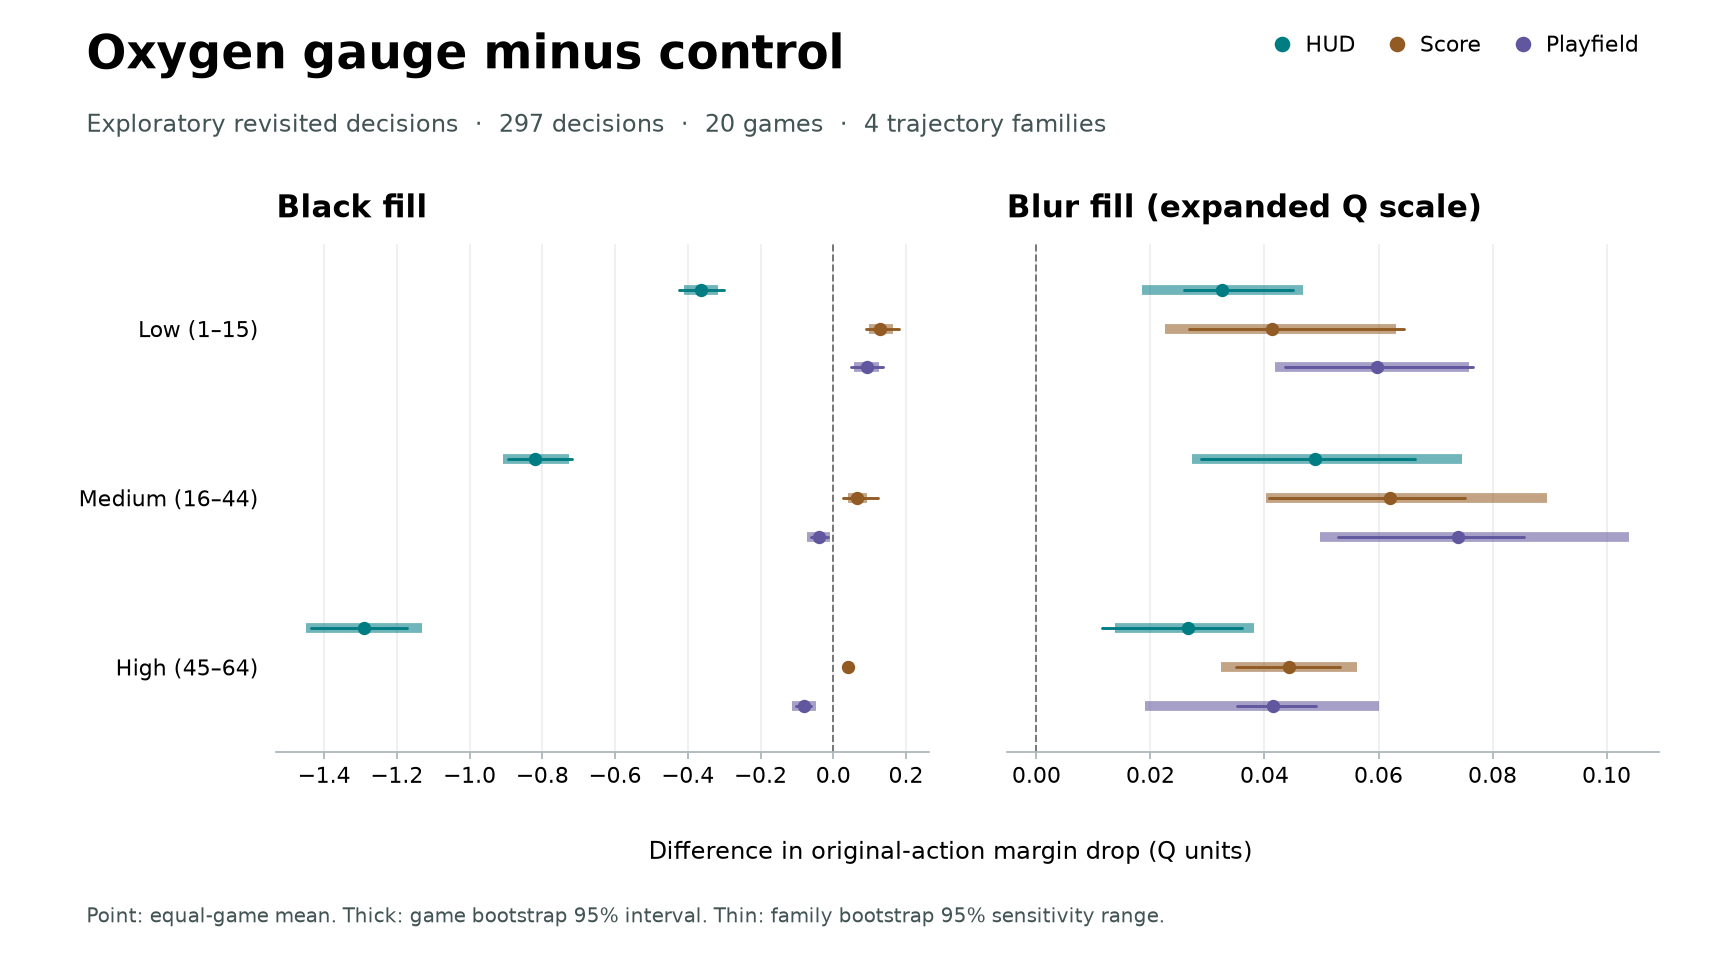

In [9]:
revisited_dir = work / "runs" / "t08-revisited-v1"
revisited = json.loads(checked_file(
    revisited_dir / "summary.json",
    "28d02fd42450decda8344f4bca75e2d7817fdaece3c7c04ee2c828eb5536ea5d",
))
assert revisited["scope"] == "exploratory_revisited"
assert revisited["origin"]["accepted_sha256"] == signed["accepted_sha256"]
assert revisited["origin"]["qc_summary_sha256"] == signed["input"]["qc_summary_sha256"]
assert revisited["primary_signed_states"] == signed["states"] == 0
assert revisited["matching_raw_selection_rows"] == revisited["records"] == 297
assert revisited["matching_selected_selection_rows"] == 0
assert revisited["games"] == 20 and len(revisited["families"]) == 4

def revisited_rows(name):
    content = checked_file(revisited_dir / name, revisited["output_sha256"][name])
    return list(csv.DictReader(StringIO(content.decode())))

state_rows = revisited_rows("states.csv")
assert len(state_rows) == 297 and len({row["stack_sha256"] for row in state_rows}) == 292
assert Counter(row["stratum"] for row in state_rows) == {"low": 98, "medium": 99, "high": 100}
assert sum(row["converged"] == "False" for row in state_rows) == 15
assert len(revisited_rows("attributions.csv")) == 3564
assert len(revisited_rows("interventions.csv")) == 2376
assert [int(row["states"]) for row in revisited_rows("stratum_profiles.csv")] == [98, 99, 100]
assert len(revisited_rows("estimates.csv")) > 0

region_content = checked_file(
    revisited_dir / "region-content.csv",
    "27e7330f93a9864acd2390ea3a1849e13240abffc45ef3939f7de67227b8e1f6",
)
region_rows = {row["region"]: row for row in csv.DictReader(StringIO(region_content.decode()))}
assert {name: int(row["constant_stacks"]) for name, row in region_rows.items()} == {
    "oxygen": 0, "neighboring_hud": 0, "score": 0, "playfield": 90,
}
assert all((row["decisions"], row["pixels_per_frame"]) == ("297", "136")
           for row in region_rows.values())
assert region_rows["neighboring_hud"]["distinct_frame_patterns"] == "3"
runtime = json.loads(checked_file(
    revisited_dir / "measurement-runtime.json",
    "e78a192e4a83d936836059c582e2fc0ff1e77dc082627febaad686b5b469e046",
))
assert len(runtime["original_cache_sha256"]) == 20


verification = json.loads(checked_file(
    revisited_dir / "independent-verification.json",
    "85744883d7f5081f19c85522475b7954f5f004c188206bea450bf0bd9ce4115e",
))
assert verification["verified_state_fill_region_rows"] == 2376
assert verification["condition_contrasts_verified"] == 18
assert verification["flip_mismatches"] == 0
assert all(error == 0 for error in verification["max_absolute_errors"].values())

by_game = {
    (row["game_id"], row["stratum"]): row
    for row in revisited_rows("game_margin_contrasts.csv")
}
contrasts = revisited_rows("figure_source.csv")
revisited_games = sorted({game for game, _ in by_game})
family_index = [[revisited_games.index(game) for game in group] for group in revisited["families"]]
assert len(by_game) == 60 and len(contrasts) == 18
assert all(verification["sources_sha256"][name] == revisited["output_sha256"][name]
           for name in ("figure_source.csv", "game_margin_contrasts.csv"))
rng_seed = revisited["bootstrap"]["seed"]
draws = np.random.default_rng(rng_seed).integers(20, size=(20000, 20))
family_draws = np.random.default_rng(rng_seed).integers(4, size=(20000, 4))
for row in contrasts:
    key = f'{row["fill"]}_oxygen_minus_{row["control"]}'
    values = np.array([float(by_game[game, row["stratum"]][key])
                       for game in revisited_games])
    bounds = np.quantile(values[draws].mean(axis=1), [.025, .975])
    assert np.allclose([values.mean(), *bounds],
                       [float(row[k]) for k in ("estimate", "lo95", "hi95")],
                       rtol=0, atol=1e-12)
    sums = np.array([values[group].sum() for group in family_index])
    counts = np.array([len(group) for group in family_index])
    resampled = sums[family_draws].sum(axis=1) / counts[family_draws].sum(axis=1)
    family_bounds = np.quantile(resampled, [.025, .975])
    assert np.allclose(family_bounds, [float(row[k]) for k in ("family_lo95", "family_hi95")],
                       rtol=0, atol=1e-12)

figure = checked_file(revisited_dir / "margin_contrasts.png", "d4565bf6ae14b752e83db57fac190aa4d182c6f00efdd730bcd74e0079769461")
assert sha256(figure).hexdigest() == revisited["output_sha256"]["margin_contrasts.png"]
display(Image(data=figure, width=720))

### Attribution, action and state context

Gauge attribution and pixel effects tell different stories. The gauge’s share of positive IG attribution was 6.21%, 9.88% and 12.05% in low, medium and high oxygen, while its gauge-only black margin drop decreased from 0.1569 Q at low oxygen to 0.0760 Q at high oxygen. At low oxygen the gauge-minus-HUD occlusion density was 0.00098 in native units (descriptive interval -0.00167 to 0.00371), while blur produced a positive gauge-minus-HUD margin contrast.

At low oxygen, gauge-minus-HUD action flips changed by -14.25 percentage points in black and +30.25 points in blur. The upward-preference contrast at low oxygen had intervals spanning zero in both fills (black -0.01261 to 0.03922 Q, blur -0.01650 to 0.01814 Q). Across strata, average raw depth (RAM byte 97) was 69.71, 68.26 and 61.98, average collected divers were 0.47, 0.57 and 0.23, and pre-intervention margins were 0.0402, 0.0187 and 0.0254 Q. These differences describe the cohort context. The pixel treatments leave actual oxygen and game dynamics fixed.

## RQ3. Patterns before life loss

**Exploratory answer.** The last eligible decision before life loss occurred at low oxygen (3) in one case and high oxygen (45) in the other. Both later show zero oxygen alongside changes in action or animation. The event marker identifies the drop in remaining lives, and the cause remains unknown. These event windows are exploratory and are distinct from the ordinary-state RQ2 cohort.

### Event selection and control matching

The protocol indexes the 24 consecutive decisions ending at the life-loss action $t$. Its attribution anchor is the last preceding decision in that window with an eligible four-frame history. The protocol selects one low (1-15) and one medium/high (16-64) event by game and step, preferring different games. Local file timestamps place the final selection rules before the event-data download and case selection on 22 November. The rules were uploaded after case selection, so this ordering relies on local timestamps.

Of 80 events, 53 lacked an eligible anchor and 27 remained (4 low, 23 medium/high). The 42,453 history-eligible decisions yielded 41,946 candidate controls after the window and follow-up filters. The chosen event pairs had 7,404 and 15,504 same-stratum candidates after the matching exclusions. The protocol prefers the same game, a final UP-family action, then closer oxygen and depth before game and step tie-breaks. A valid control has no life loss in its window and its 24-step follow-up.

**Table 5. Case anchors and observation windows.** Time is the zero-based decision index. Margins use DQN Q units and depth is RAM[97]. Each entire window comprises 24/24 inputs also seen in the raw selection trajectories.

| Window | Game / steps | Anchor | Oxygen | Depth | Action | Margin |
| --- | --- | ---: | ---: | ---: | --- | ---: |
| Low event | g1020 / 1813-1836 | 1813 | 3 | 57 | UPLEFTFIRE | 0.03819 |
| Low control | g1020 / 1788-1811 | 1811 | 3 | 65 | UPLEFTFIRE | 0.13751 |
| High event | g1010 / 2303-2326 | 2303 | 45 | 60 | RIGHTFIRE | 0.02926 |
| High control | g1010 / 152-175 | 175 | 45 | 70 | UPFIRE | 0.00626 |

The windows in each pair share zero four-frame stacks with each other. The low control’s follow-up overlaps the paired event’s pre-loss trajectory. That control reached the same loss one decision beyond its 24-step follow-up. Comparison windows describe what was seen within the specified horizon.

## RQ3. Low-oxygen event and comparison window

**Figure 5.** Low-oxygen event and matched comparison window. The blue line identifies the attribution anchor and the orange line marks the life-loss action. Maps have separate color scales. The same-game control window ends at decision 1811. The agent survives the 24-step follow-up through 1835 and loses a life at 1836. Because the paired event window ends at that same loss, this control provides no independent evidence of a safer trajectory. The full-resolution four-window figure is bundled with the notebook.

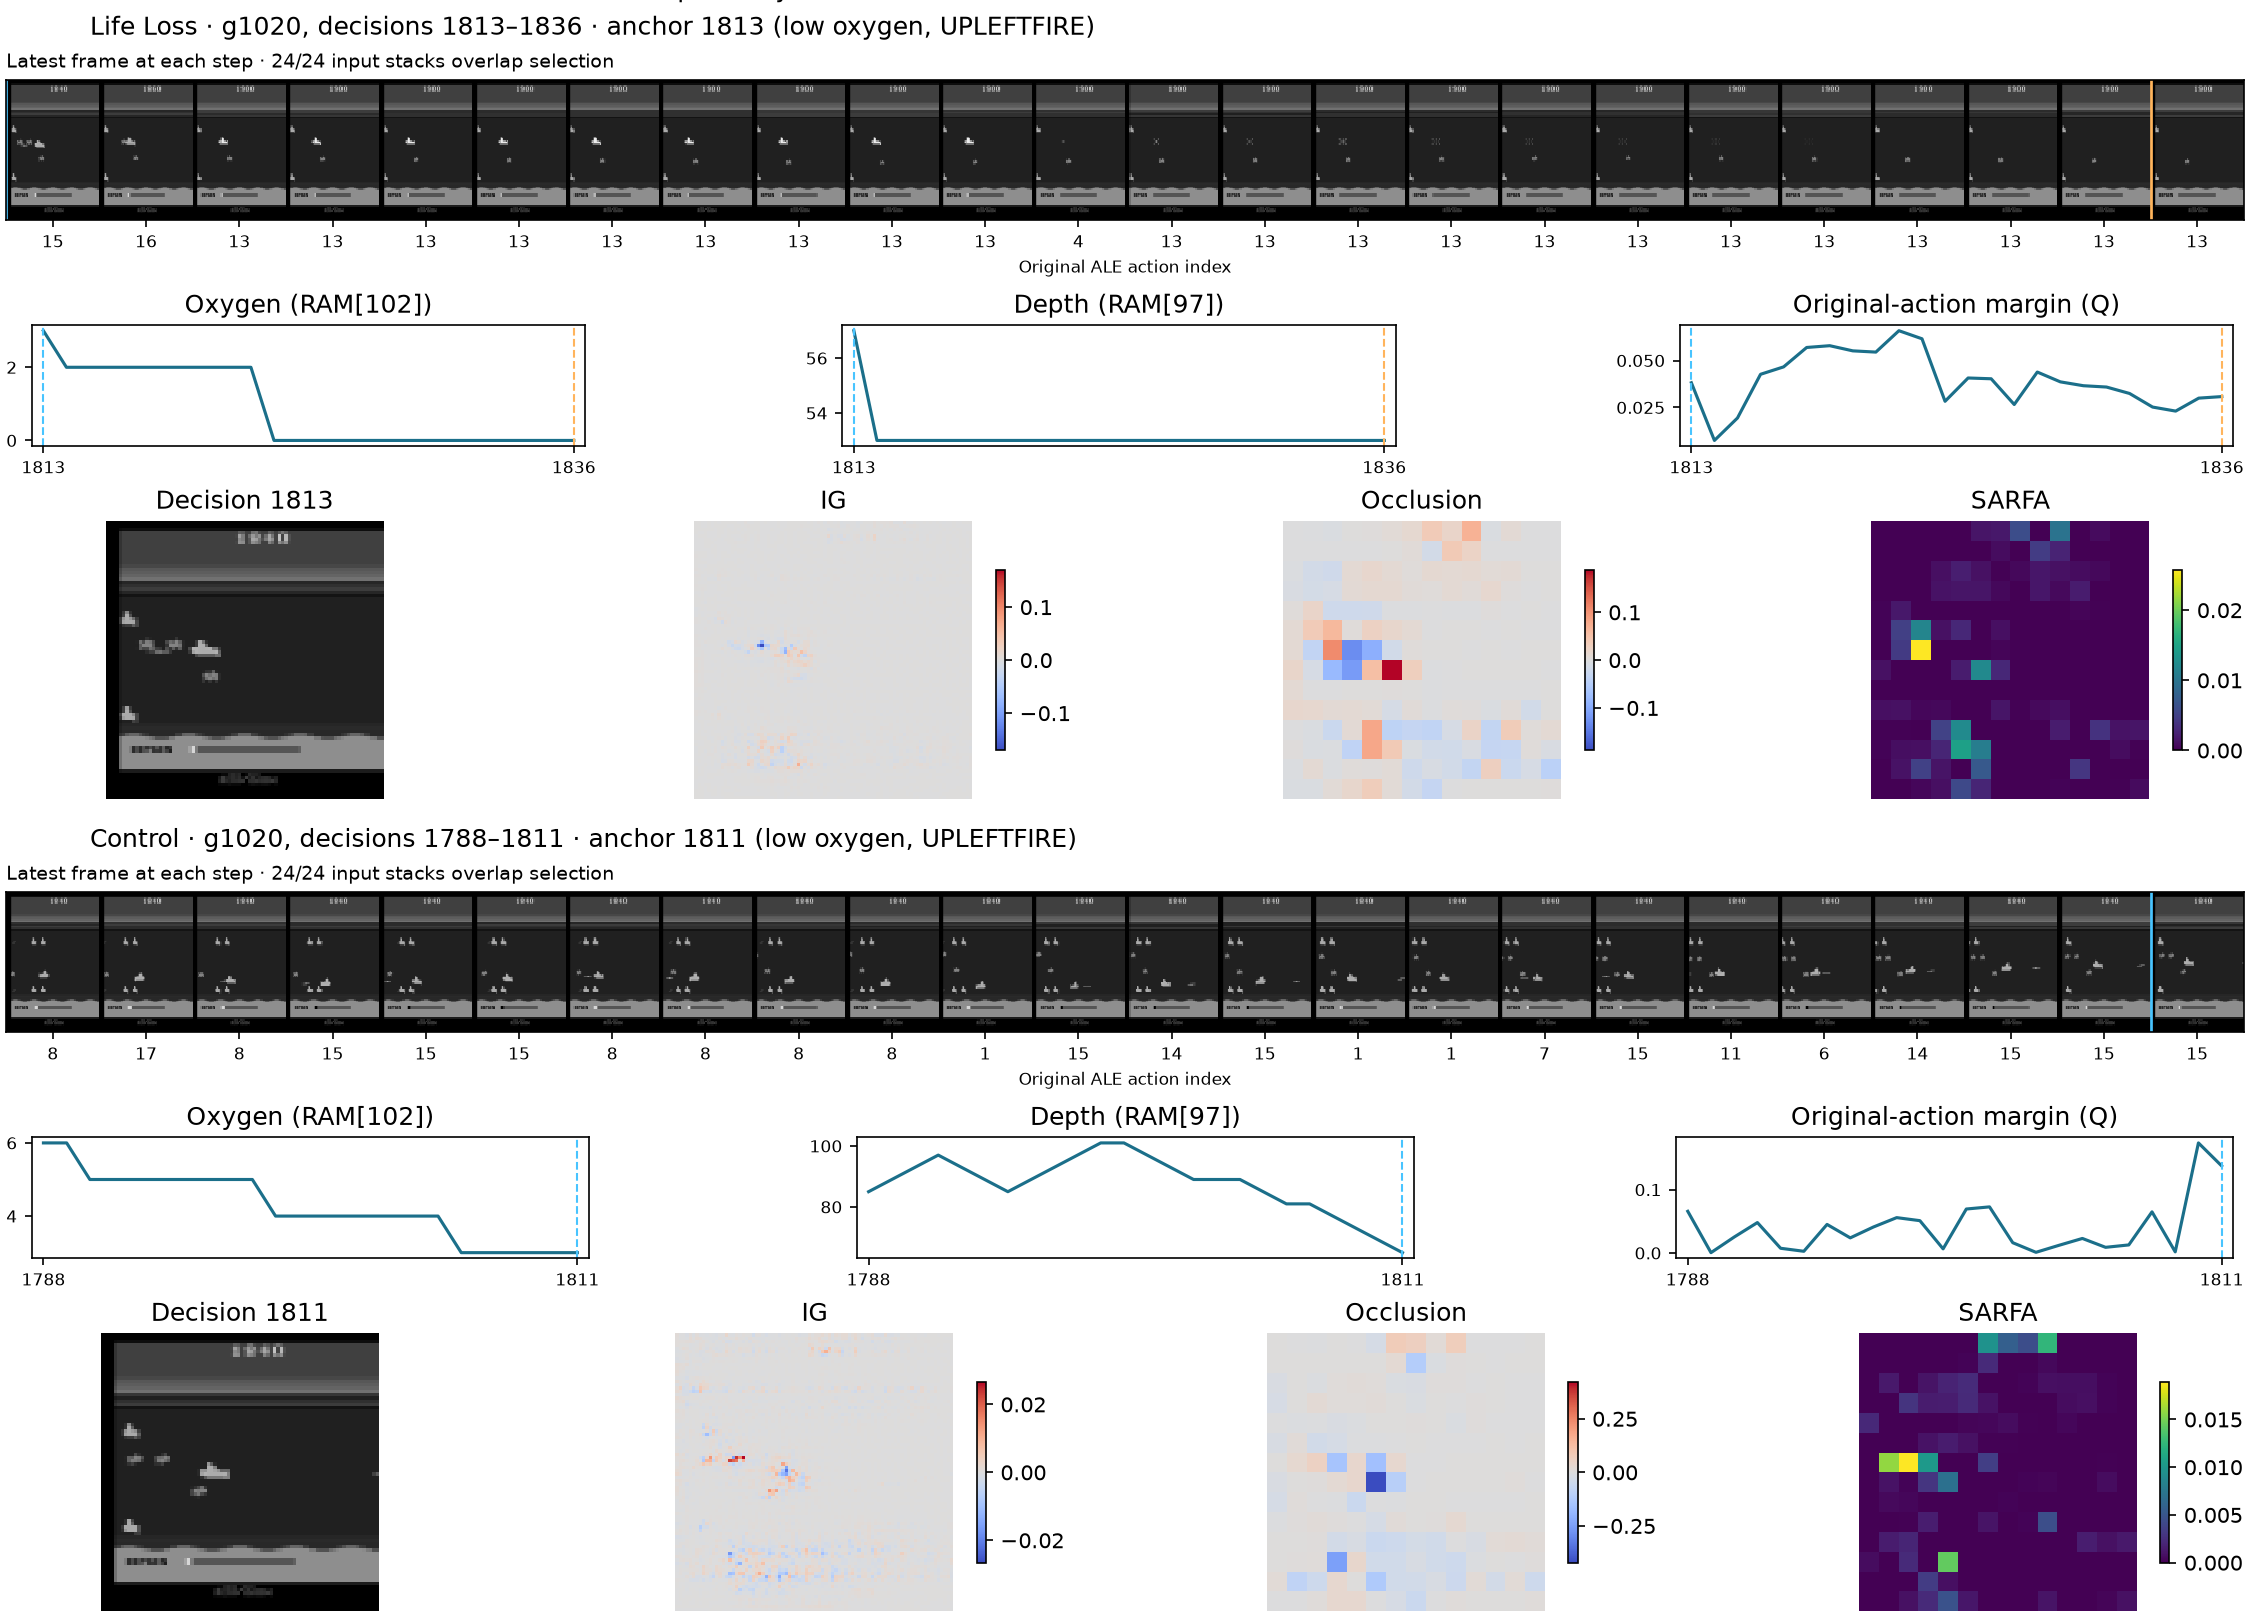

In [10]:
from io import BytesIO
from PIL import Image as PillowImage

t09_dir = work / "runs" / "t09-pr21-040fd7c"
plan_bytes = checked_file(
    t09_dir / "results" / "case-plan.json",
    "eca1b47cfce009121786bfab1ffed90c36d2257d175796be683cd0e0c5efb038",
)
case_plan = json.loads(plan_bytes)
case_protocol = json.loads(checked_file(
    t09_dir / "protocol.json", case_plan["protocol_sha256"],
))
case_render = json.loads(checked_file(
    t09_dir / "results" / "render.json",
    "2973a37fe89cd1b5f36435307b64047b4a0687b2819642e4b971ed907416e408",
))
checked_file(t09_dir / "README.md", "b0bfce24b4c419f71cb8f634183ee294aac0d64d14cac0db57c63b38f79672e4")

timing_note = checked_file(
    t09_dir / "preregistration.md",
    "ef37380e90178fece2da283a9fb01889078077e6e035f7a882249d27a4a81195",
).decode()
assert all(marker in timing_note for marker in ("19:27:57", "20:45:03", "20:55:00", "20:55:53"))

assert case_render["plan_sha256"] == sha256(plan_bytes).hexdigest()
assert case_render["freeze_sha256"] == signed["accepted_sha256"]
assert case_plan["audit_summary_sha256"] == signed["input"]["qc_summary_sha256"]
assert case_protocol["window_decisions"] == case_protocol["minimum_control_survival_decisions"] == 24
assert (case_plan["indexed_events"], case_plan["eligible_events"], case_plan["eligible_controls"]) == (80, 27, 41946)
assert [c["eligible_events"] for c in case_plan["cases"]] == [4, 23]
assert [c["eligible_controls"] for c in case_plan["cases"]] == [7404, 15504]
assert all(anchor["ig"]["converged"] for anchor in case_render["anchors"])

window_records = [case[kind] for case in case_plan["cases"] for kind in ("event", "control")]
window_ids = [(rec["game_id"], rec["start"], rec["end"], rec["anchor"]) for rec in window_records]
assert window_ids == [
    ("g1020", 1813, 1836, 1813), ("g1020", 1788, 1811, 1811),
    ("g1010", 2303, 2326, 2303), ("g1010", 152, 175, 175),
]
assert all(len(rec["steps"]) == rec["raw_overlap_steps"] == 24 for rec in window_records)
for rec in window_records:
    assert [step["decision_step"] for step in rec["steps"]] == list(range(rec["start"], rec["end"] + 1))
low_event, low_control, high_event, high_control = window_records
assert low_event["end"] - low_control["end"] == 25
assert low_event["steps"][-1]["lives"] > low_event["steps"][-1]["next_lives"]
assert high_event["steps"][-1]["lives"] > high_event["steps"][-1]["next_lives"]

case_review = json.loads(checked_file(
    t09_dir / "crosscheck.json",
    "62f1f68a257232303c77720eeb05e8ef26df7fb71ae300ab97bb5b5e884f68aa",
))
assert case_review["reviewed_commit"] == "040fd7cf3fd980cdd167b1f90694832d0797f29d"
assert case_review["plan_sha256"] == case_render["plan_sha256"]
assert case_review["independently_matched_rows"] == sum(len(rec["steps"]) for rec in window_records) == 96
assert case_review["converged_ig_anchors"] == 4 and case_review["rerun_max_q_error"] == 0
low_control_check = next(row for row in case_review["case_stats"] if row["anchor"] == 1811)
assert (low_control_check["next_loss"], low_control_check["steps_to_next_loss"]) == (1836, 25)


case_png = checked_file(
    t09_dir / "results" / "case_windows.png",
    "6a603e32652c130423f8309399d836303d7c78ad6e50b45eb586814509de8c86",
)

assert case_review["original_png_sha256"] == sha256(case_png).hexdigest()

def show_case_pair(top, bottom):
    with PillowImage.open(BytesIO(case_png)) as original:
        assert original.size == (2250, 3270)
        with BytesIO() as panel:
            original.crop((0, top, 2250, bottom)).save(panel, format="PNG")
            display(Image(data=panel.getvalue(), width=960))

show_case_pair(28, 1650)

The low event began at decision 1813 with oxygen 3 and UPLEFTFIRE. Oxygen reached zero at 1823. At the terminal life-loss action (1836), the agent chose DOWNFIRE and lives changed from one to zero. The same-game control had oxygen 3 and UPLEFTFIRE at its final decision. Its 24-step follow-up (1812-1835) shares 23 decision indices with the later event window.

## RQ3. High-oxygen event and comparison window

**Figure 6.** High-oxygen event and matched comparison window. Timelines use zero-based decisions. The frozen IG, occlusion and SARFA maps describe the highlighted anchor decisions and use individual color scales. The 24 decisions in each window recur in the raw selection trajectories.

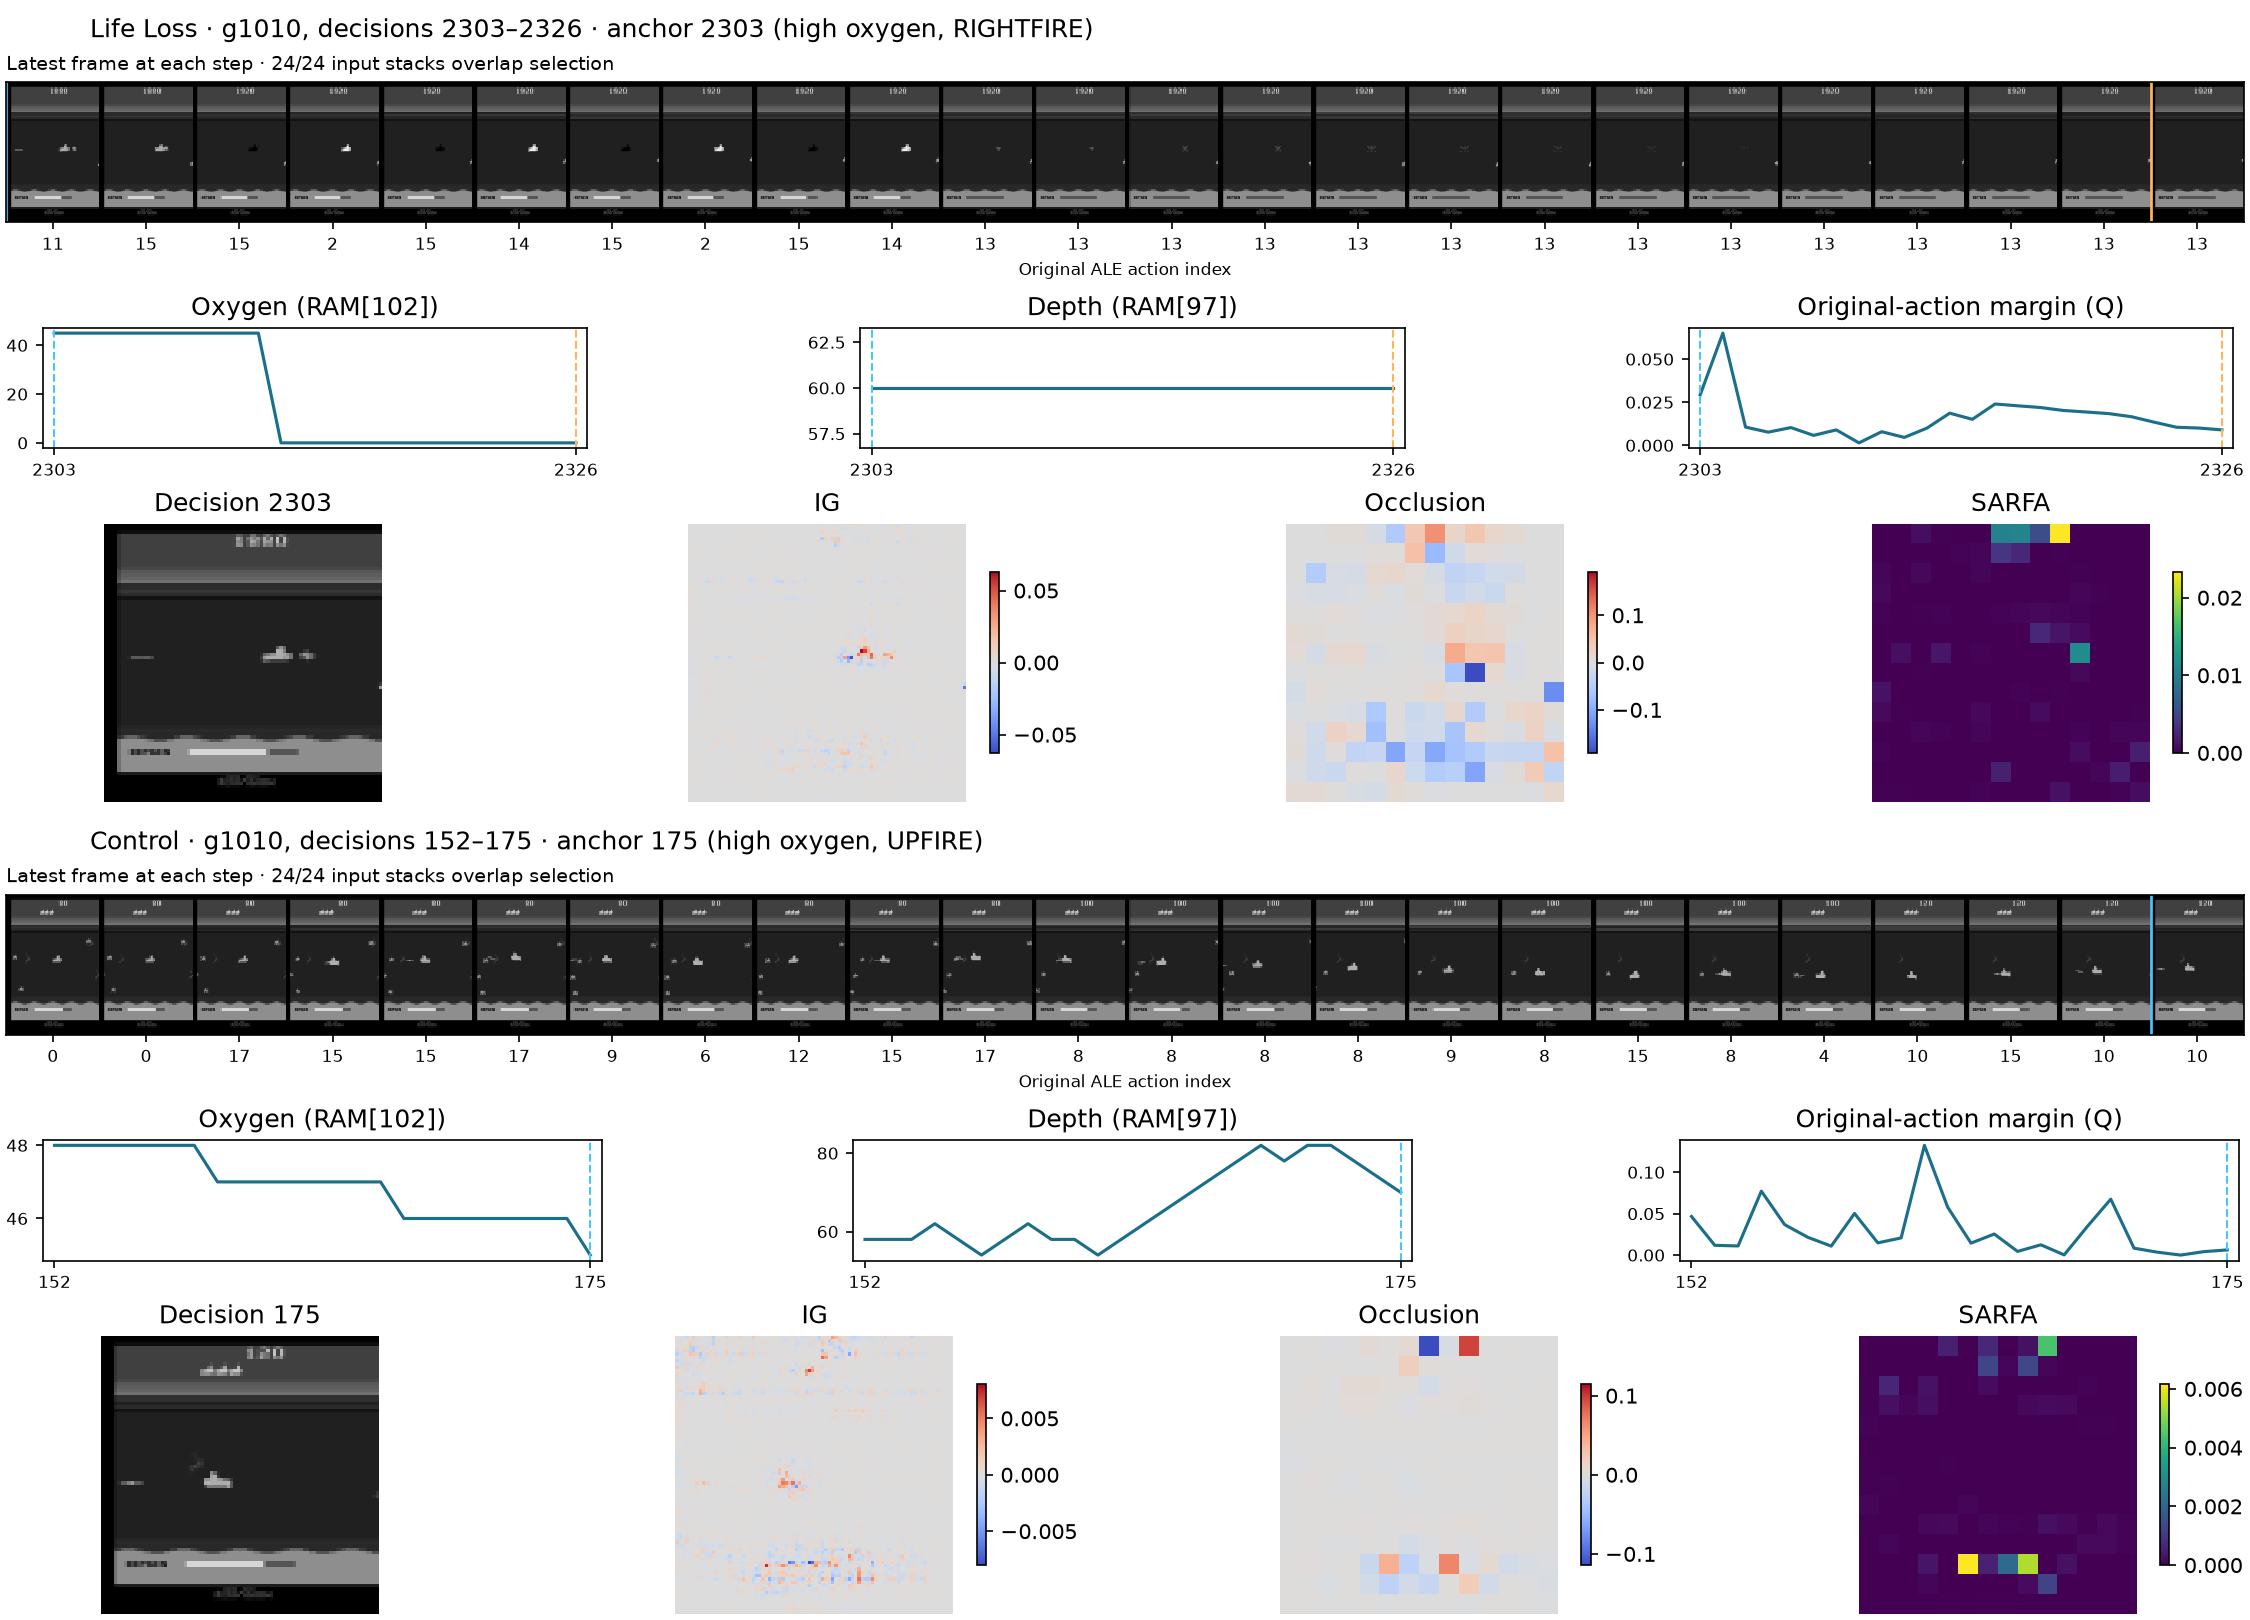

In [11]:
show_case_pair(1650, 3270)

The high event’s last eligible anchor was decision 2303 at oxygen 45, with RIGHTFIRE and depth RAM[97] of 60. Oxygen changed from 45 to 0 at 2313. Depth stayed at 60 during the window, and the agent selected DOWNFIRE from 2313 through the loss at 2326. The contrast with the low event concerns their visible lead-up. It leaves the death mechanisms unresolved.

JIN’s four anchor actions matched on replay (maximum absolute Q discrepancy $9.54 \times 10^{-7}$), and all four IG maps met tolerance. QIAN’s separate review matched the 96 source rows, action pairs and four IG checks, with maximum Q error 0 on that machine. Its rerender differed in 3,180 of 7,357,500 pixels, so Figures 5 and 6 use JIN’s archived PNG. The notebook includes the replay checks and the archived figure.

## Attempts and deviations

**Feasibility rollouts and attribution.** Three convenience-game rollouts (seeds 0-2) reached game over with raw scores 3,060, 1,900 and 1,720. One state per oxygen stratum yielded finite maps from the three methods. All three feasibility IG states passed at 1,024 integration steps. These checks establish executable inputs and outputs.

**Pilot comparison and rank sensitivity.** We checked all 96 deletion and insertion paths in the common-grid pilot. When QIAN regenerated the maps across environments, array differences reached $2.39 \times 10^{-6}$ and exact sorting changed up to 103 of 196 rank positions for one near-tied SARFA map. Seven flip flags changed and the largest margin AUC difference was 0.027563 Q units. Re-running the pilot from the original saved maps reproduced every rank order and flip flag. The formal run preserves the declared exact-tie rule and archives its actual arrays and orders.

**History and region filters.** In the first selection game, checking the latest frame alone admitted stacks containing older transition frames. We therefore applied the filter to all four frames before sampling the ten games. The old same-row HUD mask overlapped the oxygen gauge by 36 pixels per frame. The two-flank precheck explored one equal-area alternative. The accepted protocol froze a separate neighboring HUD rectangle, with the same area and zero overlap.

**Selection-data audit.** The first raw validator treated an OS-patch difference as an environment mismatch. The corrected check records collector OS versions separately and checks the shared ROM, wrapper chain, packages and action order. An initial independent-loader check called a keyword-only loader argument positionally. After correction, the audit passed; archive data were preserved.

**Independent benchmark replay.** With fresh predictions, QIAN's review found 86/120 changed full occlusion orders and 87/120 changed full SARFA orders. Every top cell, all eight aggregate rankings and the retained set persisted. All three original IG convergence failures were reproduced in spot checks. The model-randomization results in RQ1 use cosine similarity between signed cell means.

**Export test.** The mixed-script export test used the phrase “氧气”. Default XeLaTeX settings omitted the Chinese characters. The PDF uses a TrueType CJK font that preserves the characters in print and extracted text.

## Conclusions and limits

**RQ1.** IG produced the strongest deletion effect on the action margin under both fills. SARFA performed best on blur insertion. No method dominated under the frozen comparison. Near-tied rankings and IG integration failures limit fine-grained interpretation.

**RQ2.** The original deterministic collection yielded 0/300 isolated decisions. The 297 revisited observations suggested fill-sensitive reliance. The 300 isolated sticky-action inputs reproduced the sign pattern across all three strata: blackening the adjacent HUD disrupted the margin more than blackening the gauge, and blurring the gauge disrupted it more than blurring the HUD. All three positive-attribution shares rose with oxygen. The black gauge-only margin drop dipped at medium oxygen, while the HUD drove the widening black contrast. These are within-stratum estimates; a difference between strata was not tested. The pixel interventions measure immediate action support.

**RQ3.** The low- and high-oxygen anchors both preceded life loss. The low-oxygen control reached the same loss one decision beyond its follow-up. These cases cannot identify a cause of death. Whole-game resampling preserves paired comparisons, and repeated trajectories limit the original cohort's generality. Changing actual oxygen resources or evaluating longer-term behavior would require a separate experiment.


## Reproduction and peer review

**Experiment versions.** The embedded evidence identifies the selection dataset, the reviewed method comparison, and the integrity audit for the original held-out games.

**Experiment environments.** The selection run used Python 3.13.13, NumPy 2.5.4, Torch 2.15.0, SB3 2.9.2, Gymnasium 1.4.0, ALE 0.12.1 and OpenCV 5.0.0. The method comparison used Python 3.12.14, NumPy 2.5.5, Torch 2.15.0 and Captum 0.9.0. The revisited-cohort measurements used four single-threaded CPU workers.

The original experiment code reconstructed the policy inputs and replayed the checkpoint against recorded actions. This report reproduces the tables and figures using the embedded experiment records.

**Run this notebook.** In Jupyter with Python, NumPy 2+, Matplotlib, Pillow and IPython, restart the kernel and run all cells. The first code cell verifies and unpacks the embedded data. Later cells check the model digest against the replay records. The software versions for the sticky-action cohort are in `sticky/environment.json`. The report runs offline without an emulator or model download.

| Reviewer | Independent check |
| --- | --- |
| JIN Yupeng | Replayed the first selection game, checked all 20 original held-out archives and reproduced the table and plot for 297 revisited decisions. |
| QIAN Yuwei | Checked the method comparison and replayed the life-loss cases from raw trajectories. |

JIN’s report check covered all 18 revisited contrasts, the game and trajectory-family intervals, and the source figure. For the sticky cohort QIAN’s separate replay matched all 300 chosen actions. The 5,400 Q values differed by at most $1.91 × 10^{-6}$ Q, and all 18 means and interval endpoints agreed within $4.52 × 10^{-7}$ Q.


In [12]:
checkpoint_sha256 = "a626696d252c6260733e9c16b4f6d15c2227021d212e4ffaaa0cd164f726c66f"
validation_dir = work / "runs" / "validation"
t01 = json.loads(checked_file(
    validation_dir / "g1000-independent-replay.json",
    "a67a609741ace64a797e2e8a260ea65cd2950f35d2559171a0eba986be691c8b",
))
audit = json.loads(checked_file(
    validation_dir / "t03-independent-audit.json",
    "62874802d2e6860713478664838cd392539219c13b4b77c819c1f5d921bff3e6",
))
readback = json.loads(checked_file(
    work / "releases" / "t03-selection-v1" / "readback" / "member-readback.json",
    "1f01edf35729cf15d27f32789e36028565fa7b6ab32fb11d557ac7e26a4ed5fd",
))
assert t01["checkpoint_sha256"] == summary["checkpoint_sha256"] == checkpoint_sha256
assert t01["result"] == audit["result"] == "passed"
assert t01["q_values_compared"] == 33084 and t01["max_absolute_q_difference"] == 0
assert audit["package"]["actual_smallest_step_gap_any_game"] == min(gaps)
assert audit["package"]["selected_actions_reproduced"] == len(manifest)
assert readback["inputs_npz_sha256"] == summary["sha256"]["inputs.npz"]
assert readback["q_values_compared"] == q.size and readback["max_abs_q_error"] == 0
print("Evidence checks passed for T01 and T03.")
print(f"T01 local replay: {t01['q_values_compared']:,} Q-values, max absolute difference 0.")
print(f"T03 readback: {len(games)} games, {len(manifest)} states and {q.size:,} exact Q-values.")

Evidence checks passed for T01 and T03.
T01 local replay: 33,084 Q-values, max absolute difference 0.
T03 readback: 10 games, 120 states and 2,160 exact Q-values.


In [13]:
pilot_dir = work / "integration" / "seaquest_feasibility" / "results"
smoke = json.loads(checked_file(
    pilot_dir / "smoke_summary.json",
    "f6c313809d99ada03b64de8239a48e43dc05803425b476343027874306f63e14",
))
pilot = json.loads(checked_file(
    pilot_dir / "xai_pilot.json",
    "19bb903d64243fe17296088849496594608f9ea7a9bd05721dca3440c17e60d3",
))
assert smoke["checkpoint_sha256"] == checkpoint_sha256
assert [int(game["raw_score"]) for game in smoke["episodes"]] == [3060, 1900, 1720]
assert len(pilot["samples"]) == 3 and all(
    sample["all_attributions_finite"] and sample["ig_converged"] and sample["ig_steps"] == 1024
    for sample in pilot["samples"]
)

# T05 integrity summary supplies collection counts only.
t05 = json.loads(checked_file(
    work / "integration" / "seaquest_study" / "evidence" / "t05" / "integrity.json",
    "2a81c777facc1b2d04a9cd61f89d5f2f67079faed498255b5c1147a6581d8e78",
))
assert t05["partition"] == "analysis" and t05["checkpoint_sha256"] == checkpoint_sha256
assert (t05["verified_games"], t05["checked_decisions"], t05["life_loss_events"]) == (20, 46186, 80)
print("T05 collection QC: 20 verified games, 46,186 decisions, 80 life losses.")

T05 collection QC: 20 verified games, 46,186 decisions, 80 life losses.


## References

1. Stable-Baselines3. [Atari preprocessing wrappers](https://github.com/DLR-RM/stable-baselines3/blob/master/stable_baselines3/common/atari_wrappers.py).
2. Farama Foundation. [Arcade Learning Environment: Seaquest](https://github.com/Farama-Foundation/Arcade-Learning-Environment/blob/main/docs/environments/seaquest.md).
3. OCAtari. [Seaquest RAM extraction](https://github.com/k4ntz/OC_Atari/blob/master/ocatari/ram/seaquest.py).
4. Sundararajan, M., Taly, A., and Yan, Q. (2017). [Axiomatic Attribution for Deep Networks](https://proceedings.mlr.press/v70/sundararajan17a.html). ICML.
5. Captum. [Model interpretability for PyTorch](https://github.com/meta-pytorch/captum).
6. Puri et al. (2020). [Explain Your Move: Understanding Agent Actions Using Specific and Relevant Feature Attribution](https://arxiv.org/abs/1912.12191). ICLR. [SARFA reference implementation](https://github.com/nikaashpuri/sarfa-saliency/blob/master/sarfa_saliency.py).
7. Huber, T., Limmer, B., and André, E. (2022). [Benchmarking Perturbation-Based Saliency Maps for Explaining Atari Agents](https://doi.org/10.3389/frai.2022.903875). *Frontiers in Artificial Intelligence*, 5, 903875.
